# Stage 5: everything together, and the test, once

**The question.** Stages 2 to 4 each asked what one kind of information adds to a video's prediction. This stage puts
together the parts that earned a place, asks on validation whether the whole beats its best part, freezes every choice,
and then opens the test split, once, for every frozen model. `lift` is stage 1's target: the video's log share rate
minus the median of its creator's last 30 videos posted at least 14 days earlier.

The parts, as the earlier stages left them (validation, seen creators):

| Part | Stage | What it is | What it did |
|---|---|---|---|
| Metadata (B3) | 2 | ridge on the video's length, wordless, the creator's earlier videos, the days since the previous one and the weekday (alpha 0.1) | the only baseline that beat zero lift: +0.0007 log10, all of it the length |
| The words | 3 and 4 | Qwen3-Embedding-4B's first 1,024 numbers for each of seven text fields, and seven "the field holds text" flags, in ridge on what B3 leaves (alpha 100) | cut B3's error by 0.0097, 2.6% |
| Recent form (B1) | 2 | an exponentially weighted mean of the creator's settled log share rates, half-life 20 videos, minus the baseline | missed the MAE bar (+0.0025 [−0.0005, +0.0053] over zero lift), and was the best ranker: Spearman 0.146 inside a creator, ROC-AUC 0.588 |
| The pixels | 4 | SigLIP 2's vector of the first frame, in ridge on what B3 and the words leave (alpha 300) | added nothing: +0.0003 [−0.0002, +0.0008] |

Recent form has never been combined with anything. Stage 2 left it as a ranking signal no baseline used well, and stage 3
found that it ranks a creator's videos inside the kept clips and inside the retired ones better than the words do
(Spearman 0.242 and 0.215, against bge-small's 0.121 and 0.186): it knows something the words don't, how the creator is
doing lately. Stage 2's hand-off said a model that fits it with the others is a new model and needs its own bar, written
before its first run. Section 0 is that bar.

The pixels stay out of the combined model, as stage 4's bar decided. Stage 4's frozen image model still goes to the test
with the others, so the test says whether "the frame adds nothing" holds on videos no choice was ever made on.

The code is `src/sharerate/` (the loader, the history features, the text cache, the frames, `RidgeGram`, the bootstrap
and the metrics), with the stacking written out in the cells.

## 0. The bar for the combined model, written before its first run (rule 7)

This cell was written, and committed, before any combined model was fitted or scored.

- **The rows.** Every model is fitted on the training cell (74,552 videos, 148 creators), every setting is chosen on the
  21,332 validation rows, and the bar is judged on the seen creators' 13,646. The test split stays closed until every
  choice below is frozen.
- **The parts are frozen as their stages left them:** B3 ridge (notebook 02: no hour, alpha 0.1); the words,
  Qwen3-Embedding-4B ridge on what B3 leaves (notebook 04_image: alpha 100, 7,175 columns, solved by `RidgeGram`); recent
  form, `history.ewm_form` with a half-life of 20 videos (notebook 02's choice), which has no value where a video has
  fewer than 10 settled earlier videos. Nothing in them is chosen again here.
- **Out of fold on the training rows.** The combiner learns how far to trust each part from the training rows, so it must
  see the predictions those rows would get from parts that never saw them. B3 and the words head are refitted in
  notebook 04_image's 5 folds grouped by creator (`GroupKFold` over the training cell, penalties fixed), and each training
  row gets the predictions of fits that never saw its creator. Recent form is fitted to no label, so it needs no folds.
  Validation and test rows get the full fits.
- **Two combiners, fixed now; validation picks one.**
  1. **Stacked, linear:** least squares, with no penalty, of lift on four columns: B3's prediction, the words head's
     correction (its prediction minus B3's), recent form (0 where it has no value) and a flag for "fewer than 10
     settled earlier videos".
  2. **One boosted model:** scikit-learn's `HistGradientBoostingRegressor`, fitted to lift on B3's five inputs (log
     duration, wordless, log earlier videos, log days since the previous video, the weekday as a number), recent form
     (missing where it has no value, so the trees learn where those rows go) and the words head's correction. The words
     go in as the head's one number: 7,175 columns are too many for small trees, and the head already turns them into
     lift. Fixed: learning rate 0.05, at most 15 leaves a tree, at least 200 videos a leaf, an L2 penalty of 1, squared
     error, no early stopping, seed 2026. Only the number of trees (25 to 1,000, every 25) is chosen, by validation MAE.

  The combined model is the one with the lower validation MAE over all 21,332 rows.
- **The primary bar.** The combined model beats the stage before, stage 4's reference (B3 + 4B ridge), if the 95% paired
  creator-bootstrap interval of its validation MAE gain over the reference lies above 0 for **seen** creators, **with
  and without the 73 reposts** (2,000 draws, seed 2026).
- **The leak check,** stages 3 and 4's: inside each creator, the combined model's correction (its prediction minus the
  reference's) regressed on whether the platform kept the clip and on the lift, seen creators. If the kept flag's
  interval lies above 0, the model finds kept clips by something other than the lift, and that is reported as a leak,
  not a pass.
- **Reported, not required:** new and held-out creators; the skill score, Spearman inside a creator, ROC-AUC, PR-AUC
  and the top-10% share. Recent form was stage 2's best ranker, so a gain in ranking without one in MAE is reported as
  exactly that, and is not a pass.
- **The ablation is descriptive.** The chosen combiner is refitted on every subset of the three parts (each alone, each
  pair, all three), and each subset's validation MAE is compared with the combined model's, seen creators, with paired
  intervals: adding the parts in turn (B3, then the words, then recent form) and taking each one out. It says what each
  part carries; it is not another chance to pass.
- **If the combined model misses,** the final model is the reference, and this notebook says recent form adds nothing
  beyond the metadata and the words. Either way the combined model goes to the test, frozen, with the others.
- **What goes to the test, and the bar for the final claim,** are written in this notebook after this section's run and
  before the test is opened.
- **A miss is a miss.** A gain whose interval touches 0 is reported as a miss, never tuned until it passes.

## 1. The rows

**What.** Load the training and validation rows with their text fields, as notebooks 03 and 04_image did, and split the
training creators into the 5 folds notebook 04_image used, every creator's videos in one fold.

**Why.** The same rows and the same folds, so every part refitted here is the model its stage scored, and every
number below can be checked against the earlier notebooks (the asserts do).

**The mistake it avoids.** Loading the test split with the rest. `load_videos()` returns train and validation only; the
test rows come back only when named, in section 4, for their features, and in section 10, when the test is opened.

In [1]:
import json
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, LogisticRegression, Ridge
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from sharerate import data, frames, history, report, text
from sharerate.bootstrap import paired_creator_bootstrap
from sharerate.heads import RidgeGram
from sharerate.metrics import METRICS, eligible_creators

SEED, N_BOOT = 2026, 2_000  # the earlier stages' seed: the same 2,000 creator draws
GROUPS = ["seen", "new", "holdout"]  # targets.creator_seen, rule 3's three ways
GROUP_NAMES = {"seen": "Seen creators", "new": "New creators (training group, no training rows)",
               "holdout": "Held-out creators"}
FIELDS = list(text.FIELDS)  # caption, transcript, hook, body, payoff, on-screen text, scene description
QWEN = "Qwen/Qwen3-Embedding-4B"  # the words' encoder (notebook 04_image, Part A)
SIGLIP = "google/siglip2-so400m-patch14-384"  # the frame's encoder (notebook 04_image, Part B)
# The parts' settings, frozen by their stages (section 0): never chosen again here
B3_ALPHA = 0.1  # notebook 02, cell 24
TEXT_ALPHA = 100  # notebook 04_image, cell 14
LOGISTIC_C = 0.1  # notebook 04_image, cell 17
IMAGE_ALPHA = 300  # notebook 04_image, cell 29
HALF_LIFE = 20  # notebook 02, cell 15
MIN_CREATORS = 5  # rule 9: no number is shown for fewer than 5 creators
plt.rcParams.update({"figure.figsize": (8, 3.6), "figure.dpi": 110,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 60)

videos = data.load_videos(text=True)  # train and validation only; the text columns are never printed
posts = data.load_posting_times()  # B3's timing features
training = ((videos.time_split == "train") & (videos.creator_group == "train")).to_numpy()  # the only rows fitted on
validation = (videos.time_split == "validation").to_numpy()  # every setting is chosen here
lift = videos.lift.to_numpy()
breakout = videos.breakout.to_numpy().astype(int)
creator = videos.creator.to_numpy()
group = videos.creator_seen.to_numpy()
twin = videos.has_twin.to_numpy() == 1  # has_twin is 0/1: compare, never ~, which flips bits
seen_rows = validation & (group == "seen")  # the bar's rows

# Notebook 04_image's 5 folds (its cell 6): GroupKFold keeps each training creator's videos in one fold
folds = np.full(len(videos), -1)
train_index = np.flatnonzero(training)
for k, (_, part) in enumerate(GroupKFold(n_splits=5).split(train_index, groups=creator[train_index])):
    folds[train_index[part]] = k

cells = {"training": training} | {f"validation: {g}": validation & (group == g) for g in GROUPS}
display(pd.DataFrame({name: {"videos": rows.sum(), "creators": len(set(creator[rows])),
                             "reposts (has_twin)": (rows & twin).sum()} for name, rows in cells.items()}).T)
# The earlier notebooks' rows and folds: if these move, nothing below is comparable with them
assert (training.sum(), len(set(creator[training]))) == (74_552, 148)
assert [(validation & (group == g)).sum() for g in GROUPS] == [13_646, 2_275, 5_411]
assert [(folds == k).sum() for k in range(5)] == [14_908, 14_913, 14_912, 14_912, 14_907]

,videos,creators,reposts (has_twin)
training,74552,148,0
validation: seen,13646,138,73
validation: new,2275,27,3
validation: holdout,5411,38,18


**What it says.** The rows and folds are notebook 04_image's (the asserts hold): 74,552 training videos from 148 creators,
and 13,646, 2,275 and 5,411 validation videos from 138 seen, 27 new and 38 held-out creators, of which 73, 3 and 18 are
reposts. The 5 folds hold the same videos as there, to the video.

## 2. The parts, refitted as their stages left them

**What.** The three parts, each with its stage's frozen setting, fitted on the training cell:

- **B3:** notebook 02's ridge on metadata, no hour, alpha 0.1;
- **the words:** the 4B ridge head on what B3 leaves, alpha 100, solved by `RidgeGram` (X′X once per fold, so the
  out-of-fold fits in section 3 cost one solve each);
- **recent form:** `history.ewm_form` with a half-life of 20 videos, which needs no fitting.

Each is checked against the number its stage printed.

**Why.** The combined model is built from these exact parts, and the test scores these exact models. A part that
changed on the way here would make every comparison with stages 2 to 4 wrong.

**The mistake it avoids.** Choosing a part's setting again on this notebook's runs. Each one was chosen once, in its own
stage, and is a constant here.

In [2]:
def b3_inputs(frame):
    # B3's five inputs (notebook 02, cell 21, without the hours), for any rows of the loader
    timing = history.posting_features(frame, posts)  # from every library video posted strictly earlier
    return pd.DataFrame({
        "log_duration": np.log10(frame.duration_seconds.clip(lower=1)),  # a few videos have a duration of 0
        "wordless": frame.is_wordless,  # NaN where the labelling pipeline never reached the video
        "log_earlier_videos": np.log10(1 + timing.earlier_videos),
        "log_days_since_previous": np.log10(1 + timing.days_since_previous),
        "weekday_utc": timing.weekday_utc,
    }, index=frame.index)


NUMERIC = ["log_duration", "wordless", "log_earlier_videos", "log_days_since_previous"]


def b3_model():
    # Notebook 02's B3 ridge with no hour (cell 24): a fresh, unfitted copy
    return make_pipeline(
        ColumnTransformer([
            ("numbers", make_pipeline(SimpleImputer(strategy="median", add_indicator=True), StandardScaler()), NUMERIC),
            ("categories", OneHotEncoder(handle_unknown="ignore"), ["weekday_utc"]),
        ]),
        Ridge(alpha=B3_ALPHA),
    )


def mae(pred, rows):
    return np.abs(lift[rows] - pred[rows]).mean()


features = b3_inputs(videos)
b3 = b3_model().fit(features[training], lift[training])
predictions = {"B0 zero lift": np.zeros(len(videos)), "B3 ridge": b3.predict(features)}  # one lift per row

# Recent form: NaN where the video has fewer than 10 settled earlier videos; B1 predicts zero lift there (notebook 02)
form = history.ewm_form(videos, HALF_LIFE)
no_form = np.isnan(form)
predictions["B1 recent form"] = np.nan_to_num(form, nan=0.0)

for name in predictions:
    print(f"{name}: validation MAE {mae(predictions[name], validation):.4f}, seen creators {mae(predictions[name], seen_rows):.4f}")
print(f"Validation rows with no recent form (fewer than 10 settled earlier videos): {(validation & no_form).sum():,}")
assert round(mae(predictions["B3 ridge"], seen_rows), 4) == 0.3681  # notebook 03, cell 12
assert round(mae(predictions["B1 recent form"], seen_rows), 4) == 0.3662  # notebook 03, cell 12

B0 zero lift: validation MAE 0.3712, seen creators 0.3687
B3 ridge: validation MAE 0.3706, seen creators 0.3681
B1 recent form: validation MAE 0.3693, seen creators 0.3662
Validation rows with no recent form (fewer than 10 settled earlier videos): 943


**What.** The words: the seven fields' 4B vectors read from the rental's cache, and the ridge head on what B3 leaves.

- `text_matrix` puts the seven "the field holds text" flags first, then each field's 1,024 numbers, notebook 04_image's
  column order, for any rows of the loader (the test's too, in section 4). `refuse` stops the run if a text has no
  cached vector: on this laptop's CPU the 4B would otherwise start embedding it.
- `apply_head` is the head's prediction on rows the gram was not built from (the test's), a block at a time.

**Why.** The full fit's correction is what validation and test rows get; section 3 builds the training rows' out of fold.

**The mistake it avoids.** A text with no vector scored as an empty field: its zeros would say "no words" where there
were words. `refuse` turns that into an error.

In [3]:
def refuse(batch):
    # text.embed calls this only for texts with no cached vector: never embed on this laptop
    raise RuntimeError(f"{len(batch):,} texts have no vector in the cache: fetch them from the box (docs/gpu.md)")


def text_matrix(frame, width=1_024):
    # 7 flags, then 7 blocks of `width` numbers (zeros where the field is empty): 7 x (1 + width) columns, float32
    filled = (frame[FIELDS] != "").to_numpy()
    X = np.zeros((len(frame), len(FIELDS) * (1 + width)), dtype=np.float32)
    X[:, :len(FIELDS)] = filled
    for j, field in enumerate(FIELDS):
        block = text.embed(frame[field], QWEN, encoder=refuse)
        lengths = np.linalg.norm(block, axis=1)
        # Every non-empty field is a unit vector and every empty one is zeros (notebook 04_image, cell 11)
        assert block.shape[1] == width and np.allclose(lengths[filled[:, j]], 1, atol=1e-3)
        assert not lengths[~filled[:, j]].any()
        X[:, len(FIELDS) + j * width:len(FIELDS) + (j + 1) * width] = block
        del block
    return X


def apply_head(X, w, b, chunk=4_096):
    # X w + b in float64, a block of rows at a time (as RidgeGram.predict does for the rows it holds)
    return np.concatenate([np.asarray(X[s:s + chunk], dtype=np.float64) @ w + b for s in range(0, len(X), chunk)])


X_text = text_matrix(videos)  # 121,749 x 7,175, float32: about 3.5 GB
gram_text = RidgeGram(X_text, training, folds[training])  # X'X of each training fold, once
w_text, b_text = gram_text.fit(lift - predictions["B3 ridge"], TEXT_ALPHA)  # every fold: the full fit
words = gram_text.predict(w_text, b_text)  # the head's correction, on every row
predictions["4B ridge"] = predictions["B3 ridge"] + words
print(f"4B ridge: validation MAE {mae(predictions['4B ridge'], validation):.4f}, "
      f"seen creators {mae(predictions['4B ridge'], seen_rows):.4f}")
assert round(mae(predictions["4B ridge"], seen_rows), 4) == 0.3583  # notebook 04_image, cell 14

4B ridge: validation MAE 0.3610, seen creators 0.3583


**What it says.** Every part is its stage's model again. B3 misses the seen creators' validation videos by 0.3681, as in
notebooks 02 and 03; recent form by 0.3662, notebook 02's weighted mean with a half-life of 20; and B3 + 4B ridge by
0.3583, notebook 04_image's reference (0.3610 over all validation rows). 943 validation rows (4.4%) have fewer than 10
settled earlier videos and so no recent form: B1 predicts zero lift there, and the combined model gets the flag.

## 3. Out of fold: what each part says about training rows it never saw

**What.** For each of the 5 folds, B3 and the words head are refitted on the other four (penalties fixed), and the fold's
rows get those fits' predictions: notebook 04_image's cell 23, kept as two columns, B3's prediction and the words'
correction, instead of their sum. Validation rows keep the full fits.

**Why.** Section 0: the combiner learns how far to trust each part from the training rows. A 7,175-column head fitted
on those same rows has already absorbed part of their noise, so in sample its correction looks more trustworthy than it
is on new videos, and a combiner fitted to it would lean on the words too hard. Out of fold, each training row sees the
parts as a validation or test row does: from fits that never saw its creator.

**The mistake it avoids.** Stacking on in-sample predictions, which notebook 03's and 04_image's hand-offs warned about.

In [4]:
b3_part = predictions["B3 ridge"].copy()  # validation rows: the full fits
words_part = words.copy()
for k in range(5):
    held = folds == k
    b3_k = b3_model().fit(features[training & ~held], lift[training & ~held])  # B3 on the other four folds
    b3_pred = b3_k.predict(features)
    w, b = gram_text.fit(lift - b3_pred, TEXT_ALPHA, leave_out=k)  # the words head on what that B3 leaves
    b3_part[held] = b3_pred[held]
    words_part[held] = gram_text.predict(w, b, held)
assert ((folds >= 0) == training).all()  # every training row got its out-of-fold parts
reference_oof = b3_part + words_part  # B3 + 4B ridge, out of fold on the training rows

print(f"B3 + 4B ridge misses the training rows by {mae(predictions['4B ridge'], training):.4f} in sample and "
      f"{mae(reference_oof, training):.4f} out of fold")
print(f"The words' correction on the training rows: standard deviation {words[training].std():.4f} in sample, "
      f"{words_part[training].std():.4f} out of fold; on validation {words[validation].std():.4f}")
assert round(mae(reference_oof, training), 4) == 0.3600  # notebook 04_image, cell 23
del gram_text  # 2 GB of X'X: the folds are done, and the full fit's weights are kept

B3 + 4B ridge misses the training rows by 0.3498 in sample and 0.3600 out of fold
The words' correction on the training rows: standard deviation 0.1079 in sample, 0.1038 out of fold; on validation 0.1052


**What it says.** Out of fold, B3 + 4B ridge misses the training rows by 0.3600, against 0.3498 in sample: notebook
04_image's numbers (cell 23). The words' correction is a little smaller out of fold than in sample (a standard
deviation of 0.1038 against 0.1079) and close to its size on validation (0.1052): out of fold, the training rows see the
words the way validation and test rows do, and the combiner learns its weights from that.

**What.** The two other frozen models the test will score, refitted and checked against notebook 04_image:

- **4B logistic** (C 0.1): breakout on B3's standardised prediction and the same 7,175 text columns, for ranking
  breakouts. Its score is a log-odds, so it gets only the ranking metrics.
- **Image ridge** (alpha 300): the frame's 1,152 unit-length numbers in ridge on what the out-of-fold reference leaves,
  fitted on the training rows that have a frame; its prediction is the reference plus the head. A row with no frame gets
  the reference.

**Why.** The test scores the best of every stage, the pixels included, so the frozen image model is rebuilt
exactly: stage 4's null result on validation is checked on the test too.

**The mistake it avoids.** Fitting the image head to the in-sample reference: section 3's out-of-fold reference is what
notebook 04_image fitted it to.

In [5]:
b3_score = ((predictions["B3 ridge"] - predictions["B3 ridge"][training].mean())
            / predictions["B3 ridge"][training].std()).astype(np.float32)[:, None]  # float32: hstack keeps it
with warnings.catch_warnings():
    warnings.simplefilter("ignore")  # lbfgs' convergence note; notebook 04_image's head used the same settings
    logistic = LogisticRegression(C=LOGISTIC_C, max_iter=3_000).fit(
        np.hstack([b3_score[training], X_text[training]]), breakout[training])
scores = {"4B logistic": np.full(len(videos), np.nan)}  # breakout scores: ranking metrics only, never lifts
scores["4B logistic"][validation] = logistic.decision_function(np.hstack([b3_score[validation], X_text[validation]]))
auc = roc_auc_score(breakout[validation], scores["4B logistic"][validation])
print(f"4B logistic: C {LOGISTIC_C}, validation ROC-AUC {auc:.4f}")
assert round(auc, 4) == 0.5841  # notebook 04_image, cell 17

image, has_frame = frames.frame_vectors(SIGLIP)  # rows x 1,152, zeros where a row has no frame
image[has_frame] /= np.linalg.norm(image[has_frame], axis=1)[:, None]  # unit length (notebook 04_image, cell 26)
gram_image = RidgeGram(image, training & has_frame)
w_image, b_image = gram_image.fit(lift - reference_oof, IMAGE_ALPHA)
predictions["image ridge"] = predictions["4B ridge"] + np.where(has_frame, gram_image.predict(w_image, b_image), 0.0)
with_frame = validation & has_frame
print(f"Image ridge: alpha {IMAGE_ALPHA}, validation MAE on the {with_frame.sum():,} rows with a frame "
      f"{mae(predictions['image ridge'], with_frame):.4f}, the reference's {mae(predictions['4B ridge'], with_frame):.4f}")
assert round(mae(predictions["image ridge"], with_frame), 4) == 0.3606  # notebook 04_image, cell 29

4B logistic: C 0.1, validation ROC-AUC 0.5841


Image ridge: alpha 300, validation MAE on the 21,328 rows with a frame 0.3606, the reference's 0.3610


**What it says.** Both are notebook 04_image's models again: the 4B logistic head ranks breakouts at a validation
ROC-AUC of 0.5841, and image ridge misses the 21,328 validation rows with a frame by 0.3606, against the reference's
0.3610. They go to the test as stage 4 left them.

## 4. The test's features, built before anything is combined

**What.** The test rows' features, from the frozen parts' inputs only: B3's five inputs, the 4B vectors of their seven
text fields (embedded blind in stage 4's rental, read here with `refuse`, so nothing is embedded on this laptop) and
their frame vectors. The label columns are dropped as the rows load. Then the text and image arrays of the training and
validation rows are freed: from here on the parts are their predictions, and the frozen heads are their weights.

**Why.** Building features reads no label, so it happens before any choice, and no choice can lean
on it. And if a test text had no vector, this is where it would show, not after the test is opened.

**The mistake it avoids.** Refitting anything on the test, or building its features from it: the vocabulary-free 4B
vectors, the frames and B3's inputs come from the videos and their posting times alone. Recent form is the one feature
that reads earlier videos' share rates, the test's own among them once they are 14 days old, so it is built in section
10, when the test is opened.

In [6]:
test_videos = data.load_videos(("test",), text=True).drop(columns=["baseline", "lift", "breakout"])  # no label here
test_group = test_videos.creator_seen.to_numpy()
test_features = b3_inputs(test_videos)
X_test_text = text_matrix(test_videos)  # 4B vectors from the rental's cache: refuse() if any is missing
test_image, test_has_frame = frames.frame_vectors(SIGLIP, ("test",))
test_image[test_has_frame] /= np.linalg.norm(test_image[test_has_frame], axis=1)[:, None]  # unit length, as above

display(pd.DataFrame({g: {"videos": (test_group == g).sum(), "creators": test_videos.creator[test_group == g].nunique(),
                          "with a frame": (test_has_frame & (test_group == g)).sum(),
                          "reposts (has_twin)": (test_videos.has_twin[test_group == g] == 1).sum()} for g in GROUPS}).T)
print(f"Test texts: {int((test_videos[FIELDS] != '').to_numpy().sum()):,} non-empty fields, every one with its 4B vector")
assert [(test_group == g).sum() for g in GROUPS] == [12_455, 4_901, 4_384]  # notebook 01, cell 30

del X_text, gram_image, image  # about 4 GB: the parts are their predictions and weights from here on

,videos,creators,with a frame,reposts (has_twin)
seen,12455,138,12454,46
new,4901,39,4901,12
holdout,4384,42,4384,10


Test texts: 111,589 non-empty fields, every one with its 4B vector


**What it says.** The test holds 12,455 videos from the 138 seen creators, 4,901 from 39 new ones and 4,384 from 42
held-out ones, notebook 01's counts (the assert holds); 46, 12 and 10 of them are reposts. Every one of their 111,589
non-empty text fields has its 4B vector in the cache, so nothing was embedded here, and every test video but one has a
frame. No label was read: the rows loaded without `baseline`, `lift` and `breakout`.

## 5. The two combiners

**What.** Section 0's two combiners, fitted on the training rows' out-of-fold parts:

- **Stacked, linear:** least squares of lift on B3's prediction, the words' correction, recent form (0 where it has no
  value) and the "no recent form" flag. Its five numbers say how far it trusts each part.
- **Boosted:** gradient boosting on B3's five inputs, recent form (missing where it has no value) and the words'
  correction, its number of trees chosen by validation MAE.

The combined model is the one with the lower validation MAE over all 21,332 rows.

**Why.** The linear stack can only reweigh the parts. The boosting can also bend them: trust recent form more for one
kind of video than another, or the words more for short videos. If that matters, it wins on validation.

**The mistake it avoids.** Fitting the combiner on validation. The parts' weights come from the training rows, and
validation only picks between two models and a tree count fixed in section 0.

In [7]:
STACK = ["B3", "the words", "recent form", "no recent form"]
stack = pd.DataFrame({"B3": b3_part, "the words": words_part, "recent form": np.nan_to_num(form, nan=0.0),
                      "no recent form": no_form.astype(float)})
BOOST = ["log_duration", "wordless", "log_earlier_videos", "log_days_since_previous", "weekday_utc",
         "recent form", "the words"]
boost_columns = features.assign(**{"recent form": form, "the words": words_part})[BOOST]  # NaN stays NaN for the trees
BOOSTING = dict(learning_rate=0.05, max_leaf_nodes=15, min_samples_leaf=200, l2_regularization=1.0,
                early_stopping=False, random_state=SEED)  # section 0, fixed before the run
MAX_TREES = 1_000


def linear_stack(columns):
    # Least squares on the training rows' out-of-fold parts; predicts every row
    model = LinearRegression().fit(stack.loc[training, columns], lift[training])
    return model, model.predict(stack[columns])


def boosted(columns):
    # Fitted on the training rows; the number of trees (every 25) chosen by validation MAE over all validation rows
    model = HistGradientBoostingRegressor(max_iter=MAX_TREES, **BOOSTING).fit(boost_columns.loc[training, columns],
                                                                            lift[training])
    curve = {n: np.abs(lift[validation] - out).mean()
             for n, out in enumerate(model.staged_predict(boost_columns.loc[validation, columns]), 1) if n % 25 == 0}
    trees = min(curve, key=curve.get)
    model = HistGradientBoostingRegressor(max_iter=trees, **BOOSTING).fit(boost_columns.loc[training, columns],
                                                                        lift[training])  # the same first trees
    return model, model.predict(boost_columns[columns]), trees, pd.Series(curve, name="validation MAE")


stacked, predictions["stacked"] = linear_stack(STACK)
display(pd.Series(np.r_[stacked.intercept_, stacked.coef_], index=["intercept"] + STACK, name="weight").round(4).to_frame().T)
boosting, predictions["boosted"], trees, by_trees = boosted(BOOST)
display(by_trees.iloc[[0, 1, 3, 7, 11, 19, 39]].round(4).to_frame().T)
for name in ["4B ridge", "stacked", "boosted"]:  # six decimals over all validation rows: the choice's own number
    print(f"{name}: validation MAE {mae(predictions[name], validation):.6f}, seen creators {mae(predictions[name], seen_rows):.4f}"
          + (f" ({trees} trees)" if name == "boosted" else ""))
COMBINER = min(["stacked", "boosted"], key=lambda name: mae(predictions[name], validation))  # section 0's choice
predictions["combined"] = predictions[COMBINER]
print(f"The combined model is the {COMBINER} one")

,intercept,B3,the words,recent form,no recent form
weight,0.0238,0.6096,1.0234,0.9428,0.0058


,25,50,100,200,300,500,1000
validation MAE,0.3582,0.3564,0.3559,0.356,0.3566,0.3573,0.3584


4B ridge: validation MAE 0.361031, seen creators 0.3583
stacked: validation MAE 0.355875, seen creators 0.3528
boosted: validation MAE 0.355879, seen creators 0.3531 (150 trees)
The combined model is the stacked one


**What it says.** The stacked combiner trusts the words' correction fully (a weight of 1.02) and recent form almost
fully (0.94), and shrinks B3's prediction (0.61); the "no recent form" flag gets 0.006, next to nothing. The boosting does
best at 150 trees (0.3559) and overfits after (0.3584 at 1,000). Over all validation rows the two tie to four decimals:
0.355875 for the stacked one, 0.355879 for the boosted one. Section 0's rule takes the lower, the stacked one, by
0.000004: a coin toss between two equally good models, which lands on the simpler. Both cut the reference's 0.3610 by
about 0.005; for seen creators the stacked one misses by 0.3528, against the reference's 0.3583.

Recent form missed stage 2's bar on its own, and here it gets almost its full weight. Alone, its noise around the
typical video cost about as much as it gained; next to the words, what it knows (how the creator is doing lately) is
what the words don't.

## 6. Every model, every metric, three ways

**What.** Every lift model and the 4B logistic head on the validation rows of each creator group, with stage 2's
metrics, each with its gain over the reference (B3 + 4B ridge) and a 95% paired creator-bootstrap interval (2,000 draws,
seed 2026). Then the bar itself: the combined model's MAE gain over the reference for seen creators, with and without
the reposts.

**Why.** Section 0's bar is a paired gain over the reference; the other columns say where recent form helps, sizing the
typical video or ranking a creator's videos.

**The mistake it avoids.** Reading the bar off a table built for something else. It is computed in its own cell, on
exactly the rows section 0 names.

In [8]:
LIFT_METRICS = ["MAE", "skill"]  # need a lift; the others only need an order
DIGITS = {"MAE": 4, "skill": 4}
MODELS = ["B0 zero lift", "B3 ridge", "B1 recent form", "4B ridge", "image ridge", "stacked", "boosted", "4B logistic"]


def score_table(preds, rows, base, y=None, who=None):
    # Every metric for every prediction on `rows`, with the paired gain over `base`; logistic scores skip MAE and skill
    y = lift if y is None else y
    who = creator if who is None else who
    out = []
    for metric_name, (metric, lower_is_better) in METRICS.items():
        chosen = {m: p[rows] for m, p in preds.items() if metric_name not in LIFT_METRICS or "logistic" not in m}
        table = paired_creator_bootstrap(metric, y[rows], chosen, who[rows], base=base,
                                         lower_is_better=lower_is_better, n_boot=N_BOOT, seed=SEED)
        out.append(table.assign(metric=metric_name).rename_axis("model").reset_index())
    return pd.concat(out, ignore_index=True)


def cell(row):
    digits = DIGITS.get(row.metric, 3)
    gain, low, high = row.gain + 0.0, row.gain_low + 0.0, row.gain_high + 0.0  # + 0.0 turns -0.0 into 0.0
    return f"{row.value:.{digits}f}  {gain:+.{digits}f} [{low:+.{digits}f}, {high:+.{digits}f}]"


def show(table, order):
    display(table.assign(text=table.apply(cell, axis=1)).pivot(index="model", columns="metric", values="text")
            .reindex(index=order, columns=list(METRICS)).fillna("—"))


every = predictions | scores
validation_tables = {}
for g in GROUPS:
    rows = validation & (group == g)
    print(f"\n{GROUP_NAMES[g]}: {rows.sum():,} videos from {len(set(creator[rows]))} creators "
          f"({eligible_creators(pd.factorize(creator[rows])[0])} with at least 20, for the within-creator metrics)")
    validation_tables[g] = score_table({m: every[m] for m in MODELS}, rows, base="4B ridge")
    show(validation_tables[g], MODELS)


Seen creators: 13,646 videos from 138 creators (103 with at least 20, for the within-creator metrics)


metric,MAE,skill,spearman_within,roc_auc,pr_auc,top_decile_share
model,,,,,,
B0 zero lift,"0.3687 -0.0104 [-0.0141, -0.0069]","0.0000 -0.0559 [-0.0724, -0.0382]","0.000 -0.224 [-0.257, -0.191]","0.500 -0.092 [-0.108, -0.078]","0.241 -0.069 [-0.082, -0.058]","0.247 -0.116 [-0.154, -0.078]"
B3 ridge,"0.3681 -0.0097 [-0.0133, -0.0062]","0.0039 -0.0520 [-0.0681, -0.0348]","0.071 -0.153 [-0.194, -0.112]","0.536 -0.056 [-0.090, -0.022]","0.263 -0.047 [-0.068, -0.026]","0.290 -0.073 [-0.121, -0.024]"
B1 recent form,"0.3662 -0.0079 [-0.0128, -0.0034]","0.0336 -0.0223 [-0.0446, +0.0029]","0.146 -0.078 [-0.126, -0.030]","0.588 -0.004 [-0.028, +0.019]","0.311 +0.001 [-0.021, +0.022]","0.320 -0.042 [-0.091, +0.006]"
4B ridge,"0.3583 +0.0000 [+0.0000, +0.0000]","0.0559 +0.0000 [+0.0000, +0.0000]","0.224 +0.000 [+0.000, +0.000]","0.592 +0.000 [+0.000, +0.000]","0.310 +0.000 [+0.000, +0.000]","0.363 +0.000 [+0.000, +0.000]"
image ridge,"0.3580 +0.0003 [-0.0002, +0.0008]","0.0580 +0.0021 [-0.0002, +0.0044]","0.229 +0.005 [-0.001, +0.012]","0.592 -0.000 [-0.005, +0.005]","0.309 -0.001 [-0.006, +0.004]","0.383 +0.021 [+0.001, +0.040]"
stacked,"0.3528 +0.0055 [+0.0032, +0.0080]","0.0943 +0.0384 [+0.0272, +0.0532]","0.275 +0.051 [+0.036, +0.067]","0.630 +0.037 [+0.026, +0.050]","0.354 +0.044 [+0.031, +0.059]","0.393 +0.030 [-0.002, +0.062]"
boosted,"0.3531 +0.0052 [+0.0030, +0.0078]","0.0951 +0.0392 [+0.0265, +0.0559]","0.268 +0.044 [+0.028, +0.060]","0.628 +0.036 [+0.023, +0.049]","0.350 +0.040 [+0.026, +0.057]","0.397 +0.034 [-0.005, +0.072]"
4B logistic,—,—,"0.191 -0.033 [-0.050, -0.018]","0.588 -0.004 [-0.012, +0.004]","0.311 +0.001 [-0.009, +0.012]","0.361 -0.001 [-0.033, +0.029]"



New creators (training group, no training rows): 2,275 videos from 27 creators (20 with at least 20, for the within-creator metrics)


metric,MAE,skill,spearman_within,roc_auc,pr_auc,top_decile_share
model,,,,,,
B0 zero lift,"0.3770 -0.0100 [-0.0172, -0.0030]","0.0000 -0.0431 [-0.0769, -0.0105]","0.000 -0.209 [-0.281, -0.132]","0.500 -0.097 [-0.137, -0.045]","0.265 -0.076 [-0.124, -0.027]","0.289 -0.086 [-0.158, -0.013]"
B3 ridge,"0.3774 -0.0104 [-0.0177, -0.0038]","-0.0032 -0.0464 [-0.0780, -0.0170]","-0.013 -0.222 [-0.303, -0.150]","0.505 -0.093 [-0.149, -0.049]","0.265 -0.076 [-0.120, -0.034]","0.299 -0.076 [-0.163, +0.017]"
B1 recent form,"0.3750 -0.0080 [-0.0166, -0.0016]","0.0152 -0.0279 [-0.0742, +0.0103]","0.103 -0.106 [-0.206, -0.017]","0.580 -0.017 [-0.068, +0.025]","0.306 -0.035 [-0.089, +0.016]","0.355 -0.020 [-0.144, +0.107]"
4B ridge,"0.3670 +0.0000 [+0.0000, +0.0000]","0.0431 +0.0000 [+0.0000, +0.0000]","0.209 +0.000 [+0.000, +0.000]","0.597 +0.000 [+0.000, +0.000]","0.341 +0.000 [+0.000, +0.000]","0.375 +0.000 [+0.000, +0.000]"
image ridge,"0.3671 -0.0001 [-0.0013, +0.0010]","0.0427 -0.0004 [-0.0061, +0.0061]","0.200 -0.009 [-0.020, +0.001]","0.594 -0.003 [-0.009, +0.005]","0.337 -0.004 [-0.009, +0.005]","0.394 +0.019 [-0.004, +0.043]"
stacked,"0.3637 +0.0033 [-0.0026, +0.0073]","0.0621 +0.0189 [-0.0075, +0.0365]","0.239 +0.030 [+0.004, +0.057]","0.626 +0.028 [+0.007, +0.045]","0.349 +0.008 [-0.019, +0.032]","0.436 +0.061 [+0.000, +0.121]"
boosted,"0.3633 +0.0037 [-0.0018, +0.0073]","0.0668 +0.0236 [+0.0012, +0.0379]","0.231 +0.022 [-0.012, +0.056]","0.635 +0.038 [+0.017, +0.054]","0.353 +0.012 [-0.019, +0.039]","0.442 +0.067 [-0.012, +0.154]"
4B logistic,—,—,"0.211 +0.002 [-0.036, +0.037]","0.591 -0.006 [-0.023, +0.014]","0.340 -0.001 [-0.017, +0.016]","0.403 +0.028 [-0.028, +0.084]"



Held-out creators: 5,411 videos from 38 creators (33 with at least 20, for the within-creator metrics)


metric,MAE,skill,spearman_within,roc_auc,pr_auc,top_decile_share
model,,,,,,
B0 zero lift,"0.3752 -0.0098 [-0.0153, -0.0046]","0.0000 -0.0645 [-0.0940, -0.0336]","0.000 -0.251 [-0.297, -0.204]","0.500 -0.079 [-0.111, -0.048]","0.234 -0.050 [-0.083, -0.028]","0.228 -0.126 [-0.193, -0.059]"
B3 ridge,"0.3743 -0.0089 [-0.0145, -0.0036]","0.0054 -0.0591 [-0.0878, -0.0299]","0.083 -0.168 [-0.242, -0.097]","0.525 -0.054 [-0.102, -0.006]","0.250 -0.033 [-0.067, +0.001]","0.247 -0.107 [-0.197, -0.029]"
B1 recent form,"0.3747 -0.0094 [-0.0206, -0.0018]","0.0512 -0.0133 [-0.0577, +0.0210]","0.089 -0.162 [-0.230, -0.096]","0.631 +0.052 [-0.004, +0.094]","0.361 +0.078 [+0.017, +0.134]","0.339 -0.015 [-0.096, +0.064]"
4B ridge,"0.3653 +0.0000 [+0.0000, +0.0000]","0.0645 +0.0000 [+0.0000, +0.0000]","0.251 +0.000 [+0.000, +0.000]","0.579 +0.000 [+0.000, +0.000]","0.283 +0.000 [+0.000, +0.000]","0.354 +0.000 [+0.000, +0.000]"
image ridge,"0.3646 +0.0008 [-0.0010, +0.0022]","0.0705 +0.0060 [-0.0029, +0.0136]","0.247 -0.003 [-0.011, +0.005]","0.582 +0.003 [-0.002, +0.007]","0.287 +0.004 [-0.000, +0.009]","0.342 -0.012 [-0.041, +0.014]"
stacked,"0.3604 +0.0050 [-0.0049, +0.0112]","0.1194 +0.0549 [+0.0298, +0.0742]","0.267 +0.016 [-0.011, +0.045]","0.649 +0.070 [+0.037, +0.094]","0.387 +0.104 [+0.058, +0.142]","0.361 +0.007 [-0.040, +0.050]"
boosted,"0.3598 +0.0055 [-0.0031, +0.0109]","0.1232 +0.0587 [+0.0376, +0.0736]","0.267 +0.017 [-0.014, +0.048]","0.645 +0.065 [+0.035, +0.088]","0.379 +0.095 [+0.051, +0.135]","0.372 +0.018 [-0.039, +0.069]"
4B logistic,—,—,"0.232 -0.018 [-0.042, +0.008]","0.570 -0.009 [-0.026, +0.009]","0.282 -0.001 [-0.014, +0.011]","0.333 -0.021 [-0.083, +0.031]"


**What it says.** For seen creators, the combined (stacked) model misses by 0.3528, +0.0055 [+0.0032, +0.0080] better than
B3 + 4B ridge, and 0.0159 better than zero lift's 0.3687: an error 4.3% smaller. It is now the best model on every
metric, ranking included: skill 0.094 (the reference 0.056), Spearman inside a creator 0.275 (+0.051 [+0.036, +0.067]),
ROC-AUC 0.630 (+0.037 [+0.026, +0.050]) against recent form's 0.588 and the 4B's 0.592, PR-AUC 0.354; of each creator's
top tenth by it, 39.3% broke out (+0.030 [−0.002, +0.062], an interval touching 0). The boosted model is within a few
ten-thousandths of it everywhere. The 4B logistic head ranks no better than 4B ridge (ROC-AUC 0.588 against 0.592).

For creators the model never trained on, the MAE gain over the reference crosses 0: +0.0033 [−0.0026, +0.0073] for new
creators and +0.0050 [−0.0049, +0.0112] for held-out ones. The ranking gain holds better: ROC-AUC +0.028 [+0.007,
+0.045] for new creators, and 0.649 (+0.070 [+0.037, +0.094]) for held-out ones, whose long histories give recent form
the most to work with.

In [9]:
def paired(metric, rows, base, model, preds=None, y=None, who=None):
    # The gain of `model` over `base` on `rows`, with its 95% paired creator-bootstrap interval
    preds = every if preds is None else preds
    y = lift if y is None else y
    who = creator if who is None else who
    fn, lower_is_better = METRICS[metric]
    return paired_creator_bootstrap(fn, y[rows], {base: preds[base][rows], model: preds[model][rows]}, who[rows],
                                    base=base, lower_is_better=lower_is_better, n_boot=N_BOOT, seed=SEED).loc[model]


def interval(r, digits=4):
    return f"{r.gain + 0.0:+.{digits}f} [{r.gain_low + 0.0:+.{digits}f}, {r.gain_high + 0.0:+.{digits}f}]"


bar = {label: paired("MAE", rows, "4B ridge", "combined")
       for label, rows in {"seen creators": seen_rows, "seen, without the reposts": seen_rows & ~twin}.items()}
for label, r in bar.items():
    print(f"The combined ({COMBINER}) model's MAE gain over B3 + 4B ridge, {label}: {interval(r)}")

The combined (stacked) model's MAE gain over B3 + 4B ridge, seen creators: +0.0055 [+0.0032, +0.0080]
The combined (stacked) model's MAE gain over B3 + 4B ridge, seen, without the reposts: +0.0055 [+0.0032, +0.0079]


**What it says.** Both intervals lie above 0: +0.0055 [+0.0032, +0.0080] for the seen creators, and +0.0055 [+0.0032,
+0.0079] without the 73 reposts. The gain is not memorised reposts.

## 7. The ablation: what each part carries

**What.** The chosen combiner refitted on every subset of the three parts (B3, the words, recent form): each alone,
each pair, and all three, plus zero lift for nothing at all. For each, the seen creators' validation MAE and its paired
difference from the combined model. Then the chart: the parts added in turn (B3, then the words, then recent form), each
step's gain over the step before, and each part taken out of the combined model.

**Why.** It says how much of the combined model's gain each part carries, and whether a part only helps alongside
another.

**The mistake it avoids.** Reading it as a search: section 0 made the ablation descriptive, so a subset that happens
to beat the combined model here is not chosen.

In [10]:
PARTS = {"B3": {"stacked": ["B3"], "boosted": NUMERIC + ["weekday_utc"]},
         "the words": {"stacked": ["the words"], "boosted": ["the words"]},
         "recent form": {"stacked": ["recent form", "no recent form"], "boosted": ["recent form"]}}
SUBSETS = [("B3",), ("the words",), ("recent form",), ("B3", "the words"), ("B3", "recent form"),
           ("the words", "recent form"), ("B3", "the words", "recent form")]
ablation = {"nothing (zero lift)": predictions["B0 zero lift"]}
for subset in SUBSETS:
    columns = [c for part in subset for c in PARTS[part][COMBINER]]
    ablation[" + ".join(subset)] = linear_stack(columns)[1] if COMBINER == "stacked" else boosted(columns)[1]
FULL = " + ".join(SUBSETS[-1])
assert np.allclose(ablation[FULL], predictions["combined"])  # the full subset is the combined model itself

ablation_table = paired_creator_bootstrap(METRICS["MAE"][0], lift[seen_rows],
                                          {m: p[seen_rows] for m, p in ablation.items()}, creator[seen_rows],
                                          base=FULL, lower_is_better=True, n_boot=N_BOOT, seed=SEED)
display(pd.DataFrame({"seen creators' MAE": ablation_table.value.round(4),
                      "against the combined model": [interval(r) for r in ablation_table.itertuples()]})
        .rename_axis(f"{COMBINER}, refitted on"))

,seen creators' MAE,against the combined model
"stacked, refitted on",,
nothing (zero lift),0.3687,"-0.0159 [-0.0206, -0.0108]"
B3,0.3682,"-0.0154 [-0.0201, -0.0103]"
the words,0.3593,"-0.0065 [-0.0088, -0.0045]"
recent form,0.3650,"-0.0122 [-0.0166, -0.0077]"
B3 + the words,0.3589,"-0.0061 [-0.0084, -0.0039]"
B3 + recent form,0.3642,"-0.0114 [-0.0157, -0.0070]"
the words + recent form,0.3535,"-0.0007 [-0.0013, -0.0002]"
B3 + the words + recent form,0.3528,"+0.0000 [+0.0000, +0.0000]"


**What it says.** Each part refitted alone: the words miss by 0.3593, recent form by 0.3650, B3 by 0.3682 (zero lift
0.3687). The words and recent form together reach 0.3535, more than their two gains over zero lift added up (0.0152
against 0.0094 + 0.0037 = 0.0131): each helps the other a little. B3 then adds 0.0007 [0.0002, 0.0013], its length
effect. Taking the words out costs the most (0.0114 [0.0070, 0.0157]), recent form next (0.0061 [0.0039, 0.0084]).
B3 and the words, refitted by least squares, miss by 0.3589, a hair above 4B ridge's 0.3583, which adds the two with
weights of exactly 1.

,MAE,spearman_within
B3 over zero lift,"+0.0005 [+0.0002, +0.0008]","+0.071 [+0.043, +0.101]"
+ the words,"+0.0093 [+0.0056, +0.0130]","+0.150 [+0.106, +0.194]"
+ recent form,"+0.0061 [+0.0039, +0.0084]","+0.054 [+0.039, +0.069]"
without B3,"+0.0007 [+0.0002, +0.0013]","+0.002 [-0.002, +0.006]"
without the words,"+0.0114 [+0.0070, +0.0157]","+0.113 [+0.076, +0.151]"
without recent form,"+0.0061 [+0.0039, +0.0084]","+0.054 [+0.039, +0.069]"


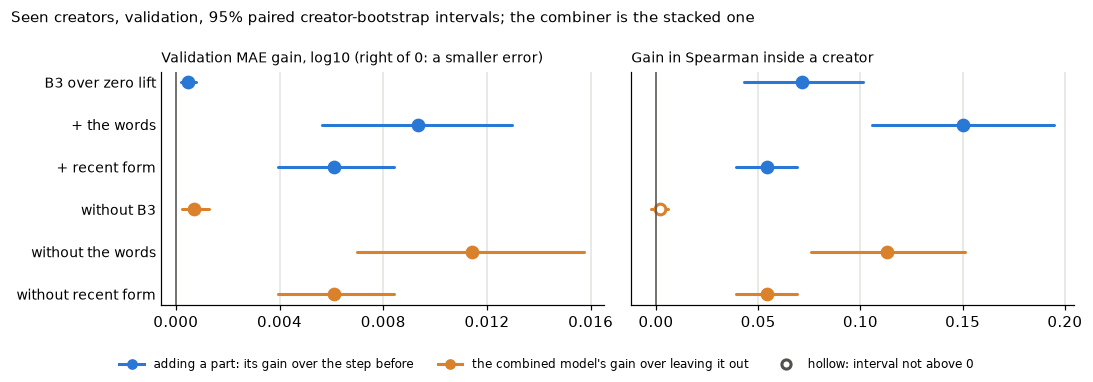

In [11]:
from matplotlib.ticker import MaxNLocator

BLUE, ORANGE, MUTED, GRID = "#2a78d6", "#d9822b", "#52514e", "#e4e3df"  # the earlier notebooks' colours
steps = [  # (label, base, model, colour): blue adds a part, orange takes one out
    ("B3 over zero lift", "nothing (zero lift)", "B3", BLUE),
    ("+ the words", "B3", "B3 + the words", BLUE),
    ("+ recent form", "B3 + the words", FULL, BLUE),
    ("without B3", "the words + recent form", FULL, ORANGE),
    ("without the words", "B3 + recent form", FULL, ORANGE),
    ("without recent form", "B3 + the words", FULL, ORANGE),
]
step_gains = {(label, metric): paired(metric, seen_rows, base, model, preds=ablation)
              for label, base, model, _ in steps for metric in ["MAE", "spearman_within"]}
display(pd.DataFrame({metric: {label: interval(step_gains[label, metric], 4 if metric == "MAE" else 3)
                               for label, *_ in steps} for metric in ["MAE", "spearman_within"]}))
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), sharey=True)
for ax, metric, title in [(axes[0], "MAE", "Validation MAE gain, log10 (right of 0: a smaller error)"),
                          (axes[1], "spearman_within", "Gain in Spearman inside a creator")]:
    for y, (label, base, model, colour) in enumerate(reversed(steps)):
        r = step_gains[label, metric]
        ax.plot([r.gain_low, r.gain_high], [y, y], color=colour, linewidth=2, solid_capstyle="round")
        ax.plot(r.gain, y, "o", markersize=7, markeredgewidth=2, color=colour,
                markerfacecolor=colour if r.gain_low > 0 else "white")
    ax.axvline(0, color=MUTED, linewidth=1)
    ax.grid(axis="x", color=GRID, linewidth=1)
    ax.set_axisbelow(True)
    ax.tick_params(axis="y", length=0)
    ax.xaxis.set_major_locator(MaxNLocator(5))
    ax.set_title(title, loc="left", fontsize=9)
axes[0].set_yticks(range(len(steps)), [s[0] for s in reversed(steps)], fontsize=9)
fig.legend(handles=[
    plt.Line2D([], [], marker="o", color=BLUE, linewidth=2, label="adding a part: its gain over the step before"),
    plt.Line2D([], [], marker="o", color=ORANGE, linewidth=2, label="the combined model's gain over leaving it out"),
    plt.Line2D([], [], marker="o", color=MUTED, markerfacecolor="white", markeredgewidth=2, linestyle="none",
               label="hollow: interval not above 0"),
], loc="lower center", ncol=3, frameon=False, fontsize=8)
fig.suptitle(f"Seen creators, validation, 95% paired creator-bootstrap intervals; the combiner is the {COMBINER} one",
             x=0.01, ha="left", fontsize=10)
fig.tight_layout(rect=(0, 0.08, 1, 1))
plt.show()

**What it says.** In turn, every step clears 0 in both panels: B3 over zero lift +0.0005 in MAE, the words +0.0093
on top of it, recent form +0.0061 on top of both. In ranking, the words add the most (Spearman inside a creator +0.15),
then B3 and recent form. Taken out, the words cost the most and B3 the least; B3's Spearman interval crosses 0, so the
metadata's length effect sizes videos without ranking them. The "+ recent form" and "without recent form" rows are the
same comparison, drawn once as a step and once as a loss.

## 8. Is the combined model finding the clips the platform kept?

**What.** Notebook 03's leak check (cell 42) on the combined model's correction over the reference, for the seen
creators' validation rows: inside each creator, the correction regressed on the kept flag and on the lift. Then Spearman
inside a creator among kept clips alone and among retired clips alone.

**Why.** Recent form reads the creator's earlier share rates, and the platform keeps each channel's top clips by share
rate (trap 3). A creator on a run has more kept clips, so a model that leans on recent form could find kept clips
through it. Given the lift, an honest correction knows nothing more about which clips were kept.

**The mistake it avoids.** Trusting that a feature built from earlier videos can't carry the platform's choice. The
`has_video` flag is used here only to split the rows, never as a feature.

In [12]:
kept = data.load_leak_reference().to_numpy().astype(bool)  # a check only: never a feature (trap 3)


def kept_given_lift(correction, rows):
    # Notebook 03, cell 42: inside each creator, correction ~ a * kept + b * lift; a with its 95% interval over draws
    codes, _ = pd.factorize(creator[rows])

    def centre(x):
        return x - pd.Series(x).groupby(codes).transform("mean").to_numpy()  # minus the creator's own mean

    k, l, y = centre(kept[rows].astype(float)), centre(lift[rows]), centre(correction[rows])
    sums = {name: np.bincount(codes, a * b) for name, (a, b) in
            {"kk": (k, k), "kl": (k, l), "ll": (l, l), "ky": (k, y), "ly": (l, y)}.items()}
    rng = np.random.default_rng(SEED)
    n = len(sums["kk"])
    weights = np.vstack([np.ones(n)] + [np.bincount(rng.integers(0, n, n), minlength=n) for _ in range(N_BOOT)])
    kk, kl, ll, ky, ly = (weights @ sums[name] for name in ["kk", "kl", "ll", "ky", "ly"])
    a = (ll * ky - kl * ly) / (kk * ll - kl ** 2)  # the 2 x 2 normal equations, solved for the kept coefficient
    alone = ky / kk  # without the lift: how far kept clips' corrections sit above retired ones' anyway
    return a[0], *np.quantile(a[1:], [0.025, 0.975]), alone[0]


print(f"Kept clips' mean lift {lift[seen_rows & kept].mean():+.3f} ({(seen_rows & kept).sum():,}), "
      f"retired clips' {lift[seen_rows & ~kept].mean():+.3f} ({(seen_rows & ~kept).sum():,})")
leak = {}
for name, base in {"combined": "4B ridge", "B1 recent form": "B3 ridge"}.items():
    a, low, high, alone = kept_given_lift(predictions[name] - predictions[base], seen_rows)
    leak[name] = {"base": base, "kept clips' correction, without the lift": f"{alone:+.4f}",
                  "given the lift": f"{a:+.4f} [{low:+.4f}, {high:+.4f}]", "low": low}
leak = pd.DataFrame(leak).T
display(leak.drop(columns="low"))

# Why the sign, if it is below 0: at the same lift, are kept clips' baselines higher, and does recent form fall as the
# baseline rises? (The platform keeps a channel's top clips by share rate, which is the baseline plus the lift.)
codes, _ = pd.factorize(creator[seen_rows])


def centred(x):
    return x[seen_rows] - pd.Series(x[seen_rows]).groupby(codes).transform("mean").to_numpy()  # inside each creator


k, l, b, f = (centred(x.astype(float)) for x in (kept, lift, videos.baseline.to_numpy(), np.nan_to_num(form, nan=0.0)))
kept_baseline = np.linalg.lstsq(np.column_stack([k, l]), b, rcond=None)[0][0]
print(f"Inside a creator, at the same lift, kept clips' baselines sit {kept_baseline:+.3f} log10 from retired clips'; "
      f"the baseline and recent form correlate at {np.corrcoef(b, f)[0, 1]:+.2f}")

ranking = {}
names = ["B3 ridge", "B1 recent form", "4B ridge", "combined"]
for label, rows in {"kept clips": seen_rows & kept, "retired clips": seen_rows & ~kept}.items():
    table = paired_creator_bootstrap(METRICS["spearman_within"][0], lift[rows], {m: predictions[m][rows] for m in names},
                                     creator[rows], base="4B ridge", n_boot=N_BOOT, seed=SEED)
    ranking[f"Spearman inside a creator, {label} ({rows.sum():,})"] = [
        f"{r.value:.3f} [{r.value_low:.3f}, {r.value_high:.3f}]" for r in table.loc[names].itertuples()]
display(pd.DataFrame(ranking, index=names))

Kept clips' mean lift +0.215 (4,719), retired clips' -0.128 (8,927)


,base,"kept clips' correction, without the lift",given the lift
combined,4B ridge,+0.0022,"-0.0216 [-0.0288, -0.0143]"
B1 recent form,B3 ridge,+0.0001,"-0.0226 [-0.0303, -0.0146]"


Inside a creator, at the same lift, kept clips' baselines sit +0.068 log10 from retired clips'; the baseline and recent form correlate at -0.67


,"Spearman inside a creator, kept clips (4,719)","Spearman inside a creator, retired clips (8,927)"
B3 ridge,"0.034 [-0.014, 0.079]","0.052 [0.018, 0.088]"
B1 recent form,"0.242 [0.180, 0.309]","0.215 [0.171, 0.259]"
4B ridge,"0.133 [0.076, 0.188]","0.186 [0.141, 0.227]"
combined,"0.264 [0.210, 0.318]","0.276 [0.235, 0.318]"


**What it says.** At the same lift, the combined model rates kept clips lower, not higher: the kept flag's coefficient is
−0.0216 [−0.0288, −0.0143], and recent form's alone over B3 is −0.0226 [−0.0303, −0.0146], so it comes from recent form.
That is the opposite of a kept-clip detector, and the printout gives the cause. The platform keeps a channel's top clips
by share rate, which is the baseline plus the lift, so at the same lift a kept clip has a higher baseline (by 0.068
log10, inside its creator); and recent form is the weighted mean of the newest settled rates minus that baseline, so it
falls as the baseline rises (the two correlate at −0.67 inside a creator). Inside each group, kept and
retired, the combined model ranks videos better than any part (Spearman 0.264 and 0.276).

## 9. The verdict, against section 0's bar

**What.** Section 0's bar applied in code: the combined model's MAE gain over the reference for seen creators, with and
without the reposts, and the leak check.

**Why.** The verdict is computed, so it can't be bent toward a pass.

**The mistake it avoids.** Calling a gain whose interval touches 0 a small win. It is a miss.

In [13]:
combined_passes = all(r.gain_low > 0 for r in bar.values()) and not leak.loc["combined", "low"] > 0
FINAL = "combined" if combined_passes else "4B ridge"  # the model the README's headline is about
verdict = pd.Series({
    "combiner": COMBINER,
    "MAE gain over B3 + 4B ridge, seen": interval(bar["seen creators"]),
    "without the reposts": interval(bar["seen, without the reposts"]),
    "finds kept clips": "yes" if leak.loc["combined", "low"] > 0 else "no",
    "beats the bar": "yes" if combined_passes else "no",
}, name="combined model")
display(verdict.to_frame())
print(f"The final model: {'the combined model' if combined_passes else 'B3 + 4B ridge (the combined model missed the bar)'}")

,combined model
combiner,stacked
"MAE gain over B3 + 4B ridge, seen","+0.0055 [+0.0032, +0.0080]"
without the reposts,"+0.0055 [+0.0032, +0.0079]"
finds kept clips,no
beats the bar,yes


The final model: the combined model


**What it says.** The combined model beats the bar: +0.0055 [+0.0032, +0.0080] over B3 + 4B ridge for seen creators, the
same without the reposts, and it finds no kept clips. It is the final model. Against zero lift it cuts the seen
creators' validation error from 0.3687 to 0.3528, by 0.0159, 4.3%. Recent form, which missed stage 2's bar alone, earns
its place next to the words.

## 10. Frozen: what goes to the test, and the bar for the final claim

This cell was written, and committed, after sections 1 to 9 ran and before the test was opened: no test label had been
read, and section 4 built the test's features without one.

**Where validation left it.** The two combiners tie to four decimals (0.3559 over all validation rows); the stacked one
is lower by 0.000004, so by section 0's rule it is the combined model, and it is also the simpler of the two. It beats
the bar: +0.0055 [+0.0032, +0.0080] over B3 + 4B ridge for seen creators, the same without the reposts, and the leak
check is clean. The final model is the combined one.

**The models that go to the test,** each frozen as this notebook built it:

| Model | Stage | Frozen as |
|---|---|---|
| B0 zero lift | 1 | the bar: lift = 0, the creator's recent median |
| B3 ridge | 2 | metadata, no hour, alpha 0.1 |
| B1 recent form | 2 | the weighted mean, half-life 20 videos; zero lift where it has no value |
| 4B ridge | 3 and 4 | B3 plus the words head, alpha 100 |
| 4B logistic | 4 | breakout, C 0.1: the ranking metrics only |
| image ridge | 4 | 4B ridge plus the frame head, alpha 300; 4B ridge where a row has no frame |
| combined | 5 | the stacked combiner, with the five weights section 5 printed |

The boosted combiner does not go: it lost on validation, and a second candidate on the test would be a second chance at
the result.

**The rows.** Every test row, in rule 3's two groups: seen creators, who have videos in the training period (138
creators, 12,455 videos), and unseen creators, new and held out together (81 creators, 9,285 videos), with the new and
the held-out ones also shown apart. 46 of the seen creators' test videos have a twin among the training videos.

**The final claim.** "The combined model predicts a video's lift better than its creator's recent median" holds on the
test if the 95% paired creator-bootstrap interval (2,000 draws, seed 2026) of its test MAE gain over zero lift lies
above 0 for **seen** creators, **with and without the reposts**. For unseen creators it is a claim of its own, made only
if their interval lies above 0 too.

**Each stage's claim is tested the same way,** as a gain over the model before it, in test MAE, for seen creators with
and without the reposts: the metadata (B3 over zero lift), the words (4B ridge over B3), recent form (the combined model
over 4B ridge) and the frame (image ridge over 4B ridge, on the rows with a frame). A claim that held on validation and
misses on the test is reported as not holding.

**Reported, not required:** the other metrics, the 4B logistic head, and the unseen creators' stage claims.

**After the test, nothing changes.** The next cell writes every choice to `reports/frozen.json`, with a fingerprint of
each model's validation predictions. Any later run of this notebook checks its choices against that file and stops if
one moved. If a bug turns up after the test is scored, it is fixed, the README says so, and both runs are reported.

In [14]:
TEST_MODELS = ["B0 zero lift", "B3 ridge", "B1 recent form", "4B ridge", "image ridge", "combined", "4B logistic"]
# A fingerprint of each model's validation predictions: a model that changed in any way changes its numbers here
fingerprints = {m: {"sum": round(float(every[m][validation].sum()), 4)}
                   | ({} if m == "4B logistic" else {"MAE": round(float(mae(every[m], validation)), 6)})
                for m in TEST_MODELS}
frozen = report._rounded({
    "settings": {"B3 ridge alpha": B3_ALPHA, "words alpha": TEXT_ALPHA, "recent form half-life": HALF_LIFE,
                 "4B logistic C": LOGISTIC_C, "image ridge alpha": IMAGE_ALPHA, "folds": 5, "seed": SEED,
                 "draws": N_BOOT},
    "combined": {"combiner": COMBINER} | (
        {"weights": dict(zip(["intercept"] + STACK, map(float, np.r_[stacked.intercept_, stacked.coef_])))}
        if COMBINER == "stacked" else {"trees": int(trees)}),
    "final model": FINAL,
    "test models": TEST_MODELS,
    "validation fingerprints": fingerprints,
})
FROZEN_FILE = data.ROOT / "reports" / "frozen.json"
if FROZEN_FILE.exists():  # every run after the first: the choices must be the ones frozen before the test
    on_file = json.loads(FROZEN_FILE.read_text(encoding="utf-8"))
    moved = [key for key in frozen if frozen[key] != on_file.get(key)]
    assert not moved, f"A frozen choice moved since the test was opened: {moved}"
    print("Every choice, and every model's validation predictions, match reports/frozen.json, "
          "written before the test was opened")
else:  # the first run: before the test is opened
    FROZEN_FILE.parent.mkdir(exist_ok=True)
    FROZEN_FILE.write_text(json.dumps(frozen, indent=1) + "\n", encoding="utf-8")
    print("Frozen: reports/frozen.json written, and the test not yet opened")
print(json.dumps({k: frozen[k] for k in ["combined", "final model", "test models"]}, indent=1))

Every choice, and every model's validation predictions, match reports/frozen.json, written before the test was opened
{
 "combined": {
  "combiner": "stacked",
  "weights": {
   "intercept": 0.023767,
   "B3": 0.609643,
   "the words": 1.023353,
   "recent form": 0.94276,
   "no recent form": 0.005841
  }
 },
 "final model": "combined",
 "test models": [
  "B0 zero lift",
  "B3 ridge",
  "B1 recent form",
  "4B ridge",
  "image ridge",
  "combined",
  "4B logistic"
 ]
}


## 11. The test, opened once

**What.** Load every split with its labels, compute the test videos' recent form, and predict every test row with
every frozen model: B3's pipeline, the words head's weights, the 4B logistic head, the image head's weights and the
combined model, each exactly as section 10 froze it. Then every metric on the seen creators' test rows and on the unseen
creators', with the gain over zero lift and its 95% paired creator-bootstrap interval, and the new and held-out
creators apart.

**Why.** Every choice in this project was made on validation, and every validation score carries a little of the luck
of the rows that chose it. The test rows chose nothing, so their scores are the honest ones.

**The mistake it avoids.** Touching a model after this. The asserts check that the rows are section 4's and that the
earlier rows' recent form is section 2's, so the test is scored on exactly what was frozen.

In [15]:
everything = data.load_videos(data.SPLITS)  # every split, labels included: the test is opened here
test = (everything.time_split == "test").to_numpy()
# The test rows are section 4's, in its order, and the other rows are section 1's
assert (everything.creator.to_numpy()[test] == test_videos.creator.to_numpy()).all()
assert (everything.published_at[test].to_numpy() == test_videos.published_at.to_numpy()).all()
assert (everything.creator.to_numpy()[~test] == creator).all() and np.allclose(everything.lift.to_numpy()[~test], lift)

# Recent form looks back only, so adding the test rows leaves the earlier rows' values as section 2 had them
form_all = history.ewm_form(everything, HALF_LIFE)
assert np.allclose(form_all[~test], form, equal_nan=True)
test_form = form_all[test]
y_test = everything.lift.to_numpy()[test]
who_test = everything.creator.to_numpy()[test]
twin_test = everything.has_twin.to_numpy()[test] == 1

# Every frozen model's prediction for the test rows
t_b3 = b3.predict(test_features)
t_words = apply_head(X_test_text, w_text, b_text)  # the words head's correction
T = {"B0 zero lift": np.zeros(test.sum()), "B3 ridge": t_b3, "B1 recent form": np.nan_to_num(test_form, nan=0.0),
     "4B ridge": t_b3 + t_words}
T["image ridge"] = T["4B ridge"] + np.where(test_has_frame, test_image @ w_image + b_image, 0.0)
t_stack = pd.DataFrame({"B3": t_b3, "the words": t_words, "recent form": np.nan_to_num(test_form, nan=0.0),
                        "no recent form": np.isnan(test_form).astype(float)})
t_boost = test_features.assign(**{"recent form": test_form, "the words": t_words})[BOOST]
T["combined"] = stacked.predict(t_stack[STACK]) if COMBINER == "stacked" else boosting.predict(t_boost)
t_b3_score = ((t_b3 - predictions["B3 ridge"][training].mean())
              / predictions["B3 ridge"][training].std()).astype(np.float32)[:, None]  # section 3's scaling
T["4B logistic"] = logistic.decision_function(np.hstack([t_b3_score, X_test_text]))

TEST_GROUPS = {"seen": test_group == "seen", "unseen": test_group != "seen",
               "new": test_group == "new", "holdout": test_group == "holdout"}
TEST_NAMES = {"seen": "Seen creators (videos in the training period)", "unseen": "Unseen creators (new and held out)",
              "new": "New creators (training group, no training rows)", "holdout": "Held-out creators"}
print(f"Test: {test.sum():,} videos posted from {everything.published_at[test].min():%Y-%m-%d} to "
      f"{everything.published_at[test].max():%Y-%m-%d}; {np.isnan(test_form).sum():,} have no recent form")
test_tables = {}
for g, rows in TEST_GROUPS.items():
    print(f"\n{TEST_NAMES[g]}: {rows.sum():,} videos from {len(set(who_test[rows]))} creators "
          f"({eligible_creators(pd.factorize(who_test[rows])[0])} with at least 20, for the within-creator metrics)")
    test_tables[g] = score_table({m: T[m] for m in TEST_MODELS}, rows, base="B0 zero lift", y=y_test, who=who_test)
    show(test_tables[g], TEST_MODELS)

Test: 21,740 videos posted from 2026-04-01 to 2026-09-18; 501 have no recent form

Seen creators (videos in the training period): 12,455 videos from 138 creators (99 with at least 20, for the within-creator metrics)


metric,MAE,skill,spearman_within,roc_auc,pr_auc,top_decile_share
model,,,,,,
B0 zero lift,"0.3752 +0.0000 [+0.0000, +0.0000]","0.0000 +0.0000 [+0.0000, +0.0000]","0.000 +0.000 [+0.000, +0.000]","0.500 +0.000 [+0.000, +0.000]","0.247 +0.000 [+0.000, +0.000]","0.253 +0.000 [+0.000, +0.000]"
B3 ridge,"0.3747 +0.0005 [+0.0000, +0.0011]","0.0047 +0.0047 [+0.0025, +0.0070]","0.078 +0.078 [+0.046, +0.115]","0.537 +0.037 [+0.016, +0.060]","0.266 +0.019 [+0.007, +0.035]","0.295 +0.042 [+0.004, +0.081]"
B1 recent form,"0.3719 +0.0033 [+0.0004, +0.0067]","0.0357 +0.0357 [+0.0222, +0.0506]","0.153 +0.153 [+0.117, +0.193]","0.597 +0.097 [+0.076, +0.125]","0.339 +0.092 [+0.071, +0.118]","0.368 +0.115 [+0.080, +0.152]"
4B ridge,"0.3649 +0.0103 [+0.0068, +0.0138]","0.0556 +0.0556 [+0.0420, +0.0703]","0.244 +0.244 [+0.208, +0.279]","0.591 +0.091 [+0.067, +0.115]","0.319 +0.072 [+0.047, +0.102]","0.394 +0.141 [+0.100, +0.185]"
image ridge,"0.3645 +0.0107 [+0.0068, +0.0145]","0.0575 +0.0575 [+0.0426, +0.0728]","0.253 +0.253 [+0.219, +0.287]","0.590 +0.090 [+0.065, +0.114]","0.318 +0.071 [+0.047, +0.100]","0.394 +0.141 [+0.101, +0.183]"
combined,"0.3595 +0.0157 [+0.0109, +0.0210]","0.0904 +0.0904 [+0.0705, +0.1113]","0.303 +0.303 [+0.270, +0.338]","0.633 +0.133 [+0.114, +0.154]","0.365 +0.118 [+0.095, +0.148]","0.435 +0.182 [+0.140, +0.227]"
4B logistic,—,—,"0.228 +0.228 [+0.194, +0.263]","0.589 +0.089 [+0.071, +0.110]","0.321 +0.074 [+0.053, +0.099]","0.380 +0.127 [+0.091, +0.167]"



Unseen creators (new and held out): 9,285 videos from 81 creators (60 with at least 20, for the within-creator metrics)


metric,MAE,skill,spearman_within,roc_auc,pr_auc,top_decile_share
model,,,,,,
B0 zero lift,"0.3774 +0.0000 [+0.0000, +0.0000]","0.0000 +0.0000 [+0.0000, +0.0000]","0.000 +0.000 [+0.000, +0.000]","0.500 +0.000 [+0.000, +0.000]","0.247 +0.000 [+0.000, +0.000]","0.236 +0.000 [+0.000, +0.000]"
B3 ridge,"0.3771 +0.0003 [-0.0002, +0.0009]","0.0027 +0.0027 [-0.0008, +0.0059]","0.042 +0.042 [-0.002, +0.089]","0.544 +0.044 [+0.020, +0.062]","0.272 +0.025 [+0.008, +0.042]","0.262 +0.026 [-0.013, +0.067]"
B1 recent form,"0.3731 +0.0043 [+0.0008, +0.0079]","0.0356 +0.0356 [+0.0211, +0.0475]","0.118 +0.118 [+0.074, +0.159]","0.590 +0.090 [+0.068, +0.115]","0.337 +0.090 [+0.055, +0.129]","0.323 +0.087 [+0.044, +0.128]"
4B ridge,"0.3707 +0.0067 [+0.0030, +0.0104]","0.0402 +0.0402 [+0.0219, +0.0550]","0.172 +0.172 [+0.124, +0.218]","0.592 +0.092 [+0.069, +0.111]","0.315 +0.068 [+0.048, +0.089]","0.334 +0.098 [+0.055, +0.142]"
image ridge,"0.3703 +0.0071 [+0.0027, +0.0116]","0.0429 +0.0429 [+0.0210, +0.0611]","0.182 +0.182 [+0.135, +0.229]","0.594 +0.094 [+0.071, +0.113]","0.316 +0.069 [+0.048, +0.091]","0.335 +0.100 [+0.059, +0.142]"
combined,"0.3650 +0.0123 [+0.0069, +0.0181]","0.0781 +0.0781 [+0.0531, +0.1008]","0.220 +0.220 [+0.177, +0.261]","0.636 +0.136 [+0.114, +0.155]","0.374 +0.127 [+0.094, +0.163]","0.383 +0.148 [+0.103, +0.191]"
4B logistic,—,—,"0.164 +0.164 [+0.119, +0.206]","0.585 +0.085 [+0.060, +0.107]","0.311 +0.064 [+0.044, +0.086]","0.316 +0.080 [+0.038, +0.125]"



New creators (training group, no training rows): 4,901 videos from 39 creators (27 with at least 20, for the within-creator metrics)


metric,MAE,skill,spearman_within,roc_auc,pr_auc,top_decile_share
model,,,,,,
B0 zero lift,"0.3679 +0.0000 [+0.0000, +0.0000]","0.0000 +0.0000 [+0.0000, +0.0000]","0.000 +0.000 [+0.000, +0.000]","0.500 +0.000 [+0.000, +0.000]","0.238 +0.000 [+0.000, +0.000]","0.231 +0.000 [+0.000, +0.000]"
B3 ridge,"0.3676 +0.0003 [-0.0004, +0.0012]","0.0042 +0.0042 [-0.0005, +0.0084]","0.039 +0.039 [-0.033, +0.114]","0.557 +0.057 [+0.021, +0.074]","0.266 +0.028 [+0.006, +0.044]","0.251 +0.020 [-0.027, +0.066]"
B1 recent form,"0.3650 +0.0030 [-0.0012, +0.0072]","0.0292 +0.0292 [+0.0163, +0.0409]","0.112 +0.112 [+0.056, +0.167]","0.580 +0.080 [+0.057, +0.115]","0.303 +0.065 [+0.049, +0.093]","0.303 +0.073 [+0.025, +0.121]"
4B ridge,"0.3613 +0.0067 [+0.0021, +0.0123]","0.0345 +0.0345 [+0.0094, +0.0566]","0.146 +0.146 [+0.072, +0.212]","0.602 +0.102 [+0.073, +0.123]","0.318 +0.080 [+0.056, +0.103]","0.314 +0.083 [+0.020, +0.148]"
image ridge,"0.3614 +0.0066 [+0.0015, +0.0127]","0.0342 +0.0342 [+0.0052, +0.0582]","0.153 +0.153 [+0.075, +0.221]","0.602 +0.102 [+0.073, +0.121]","0.317 +0.078 [+0.054, +0.102]","0.305 +0.074 [+0.007, +0.143]"
combined,"0.3579 +0.0100 [+0.0047, +0.0167]","0.0614 +0.0614 [+0.0389, +0.0826]","0.195 +0.195 [+0.130, +0.253]","0.630 +0.130 [+0.102, +0.156]","0.349 +0.111 [+0.087, +0.139]","0.344 +0.113 [+0.049, +0.177]"
4B logistic,—,—,"0.155 +0.155 [+0.090, +0.223]","0.595 +0.095 [+0.060, +0.116]","0.317 +0.079 [+0.054, +0.102]","0.313 +0.082 [+0.013, +0.163]"



Held-out creators: 4,384 videos from 42 creators (33 with at least 20, for the within-creator metrics)


metric,MAE,skill,spearman_within,roc_auc,pr_auc,top_decile_share
model,,,,,,
B0 zero lift,"0.3880 +0.0000 [+0.0000, +0.0000]","0.0000 +0.0000 [+0.0000, +0.0000]","0.000 +0.000 [+0.000, +0.000]","0.500 +0.000 [+0.000, +0.000]","0.257 +0.000 [+0.000, +0.000]","0.240 +0.000 [+0.000, +0.000]"
B3 ridge,"0.3876 +0.0003 [-0.0006, +0.0011]","0.0011 +0.0011 [-0.0040, +0.0059]","0.044 +0.044 [-0.010, +0.100]","0.529 +0.029 [-0.006, +0.058]","0.279 +0.022 [-0.001, +0.053]","0.270 +0.030 [-0.027, +0.092]"
B1 recent form,"0.3821 +0.0058 [+0.0002, +0.0107]","0.0419 +0.0419 [+0.0157, +0.0600]","0.123 +0.123 [+0.057, +0.182]","0.600 +0.100 [+0.063, +0.140]","0.369 +0.112 [+0.056, +0.160]","0.339 +0.099 [+0.035, +0.164]"
4B ridge,"0.3812 +0.0067 [+0.0009, +0.0114]","0.0458 +0.0458 [+0.0188, +0.0637]","0.193 +0.193 [+0.134, +0.253]","0.583 +0.083 [+0.046, +0.115]","0.315 +0.057 [+0.027, +0.096]","0.350 +0.110 [+0.048, +0.174]"
image ridge,"0.3803 +0.0077 [+0.0005, +0.0135]","0.0515 +0.0515 [+0.0178, +0.0731]","0.207 +0.207 [+0.152, +0.265]","0.586 +0.086 [+0.051, +0.117]","0.317 +0.060 [+0.030, +0.099]","0.360 +0.120 [+0.072, +0.176]"
combined,"0.3730 +0.0150 [+0.0059, +0.0225]","0.0947 +0.0947 [+0.0557, +0.1232]","0.240 +0.240 [+0.185, +0.295]","0.642 +0.142 [+0.108, +0.170]","0.401 +0.143 [+0.086, +0.192]","0.416 +0.176 [+0.117, +0.237]"
4B logistic,—,—,"0.171 +0.171 [+0.117, +0.224]","0.574 +0.074 [+0.038, +0.109]","0.307 +0.050 [+0.021, +0.085]","0.318 +0.078 [+0.028, +0.129]"


**What it says.** The test holds 21,740 videos posted from 1 April to 18 September 2026; 501 of them have no recent form.
For the 138 seen creators (12,455 videos), zero lift misses by 0.3752 and the combined model by 0.3595: a gain of
+0.0157 [+0.0109, +0.0210], an error 4.2% smaller, close to validation's 4.3%. It is the best model on every metric:
skill 0.090; Spearman inside a creator 0.303, against 0.244 for the words and 0.153 for recent form; ROC-AUC 0.633;
PR-AUC 0.365 against a base rate of 0.247; and of each creator's top tenth of videos by it, 43.5% broke out, against
25.3% for a random pick.

For the 81 unseen creators (9,285 videos), zero lift misses by 0.3774 and the combined model gains +0.0123 [+0.0069,
+0.0181], 3.3%, with a ROC-AUC of 0.636 and a top-10% share of 0.383 against 0.236: +0.0100 [+0.0047, +0.0167] for the
new creators and +0.0150 [+0.0059, +0.0225] for the held-out ones. Two smaller things: recent form alone clears zero lift
for seen creators on the test (+0.0033 [+0.0004, +0.0067]), which it didn't on validation, and the 4B logistic head
ranks breakouts no better than the 4B ridge (ROC-AUC 0.589 against 0.591).

**What.** Section 10's bar applied in code: each claim's MAE gain over the model before it, on the test, for seen
creators with and without the reposts and for unseen creators, beside the same gain on validation.

**Why.** The claims are what the README and the page say. Each one is kept only if the test says so.

**The mistake it avoids.** Quoting the validation number as the result. Validation chose the models; the test prices
them, and a claim that shrinks or vanishes here is reported as it is here.

In [16]:
CLAIMS = {  # claim: (model, base, rows): each stage's model over the one before it
    "The final model beats zero lift": (FINAL, "B0 zero lift", "all"),
    "Metadata beats zero lift": ("B3 ridge", "B0 zero lift", "all"),
    "The words add to the metadata": ("4B ridge", "B3 ridge", "all"),
    "Recent form adds to the metadata and the words": ("combined", "4B ridge", "all"),
    "The frame adds to the metadata and the words": ("image ridge", "4B ridge", "with a frame"),
}
claims = {}
for claim, (model, base, which) in CLAIMS.items():
    v_rows = seen_rows & (has_frame if which == "with a frame" else True)
    t_frame = test_has_frame if which == "with a frame" else np.ones(test.sum(), dtype=bool)
    t_rows = {"seen": TEST_GROUPS["seen"] & t_frame, "seen, no reposts": TEST_GROUPS["seen"] & t_frame & ~twin_test,
              "unseen": TEST_GROUPS["unseen"] & t_frame}
    on_test = {label: paired("MAE", rows, base, model, preds=T, y=y_test, who=who_test) for label, rows in t_rows.items()}
    claims[claim] = {"model": model, "base": base, "rows": which,
                     "validation": paired("MAE", v_rows, base, model), "validation_rows": v_rows,
                     "test": on_test, "test_rows": t_rows,
                     "holds": on_test["seen"].gain_low > 0 and on_test["seen, no reposts"].gain_low > 0,
                     "holds unseen": on_test["unseen"].gain_low > 0}
display(pd.DataFrame({claim: {"model over base": f"{c['model']} over {c['base']}" + (" (rows with a frame)" if c["rows"] != "all" else ""),
                              "validation, seen": interval(c["validation"]),
                              "test, seen": interval(c["test"]["seen"]),
                              "test, seen, no reposts": interval(c["test"]["seen, no reposts"]),
                              "test, unseen": interval(c["test"]["unseen"]),
                              "holds (seen)": "yes" if c["holds"] else "no",
                              "holds (unseen)": "yes" if c["holds unseen"] else "no"} for claim, c in claims.items()}).T)

,model over base,"validation, seen","test, seen","test, seen, no reposts","test, unseen",holds (seen),holds (unseen)
The final model beats zero lift,combined over B0 zero lift,"+0.0159 [+0.0108, +0.0206]","+0.0157 [+0.0109, +0.0210]","+0.0157 [+0.0108, +0.0210]","+0.0123 [+0.0069, +0.0181]",yes,yes
Metadata beats zero lift,B3 ridge over B0 zero lift,"+0.0007 [+0.0002, +0.0011]","+0.0005 [+0.0000, +0.0011]","+0.0005 [+0.0000, +0.0011]","+0.0003 [-0.0002, +0.0009]",yes,no
The words add to the metadata,4B ridge over B3 ridge,"+0.0097 [+0.0062, +0.0133]","+0.0098 [+0.0062, +0.0133]","+0.0098 [+0.0062, +0.0133]","+0.0064 [+0.0029, +0.0100]",yes,yes
Recent form adds to the metadata and the words,combined over 4B ridge,"+0.0055 [+0.0032, +0.0080]","+0.0054 [+0.0027, +0.0086]","+0.0053 [+0.0027, +0.0086]","+0.0056 [+0.0025, +0.0088]",yes,yes
The frame adds to the metadata and the words,image ridge over 4B ridge (rows with a frame),"+0.0003 [-0.0002, +0.0008]","+0.0004 [-0.0002, +0.0009]","+0.0004 [-0.0002, +0.0009]","+0.0004 [-0.0006, +0.0014]",no,no


**What it says.** Every claim that held on validation holds on the test, at almost the same size, and the one that
missed misses again. For seen creators each test gain is within 0.0002 of its validation gain: the choices made on
validation carried little of its luck.

- **The final model beats zero lift** by +0.0157 [+0.0109, +0.0210] (validation +0.0159), the same without the 46
  reposts, and by +0.0123 [+0.0069, +0.0181] for unseen creators.
- **The words add to the metadata** +0.0098 [+0.0062, +0.0133] (validation +0.0097), and +0.0064 [+0.0029, +0.0100] for
  unseen creators.
- **Recent form adds to the metadata and the words** +0.0054 [+0.0027, +0.0086] (validation +0.0055), and +0.0056
  [+0.0025, +0.0088] for unseen creators.
- **The metadata's claim holds by a hair:** +0.0005, with a lower end of +0.00004, for seen creators; for unseen
  creators its interval crosses 0 (+0.0003 [−0.0002, +0.0009]).
- **The frame adds nothing on the test either:** +0.0004 [−0.0002, +0.0009] for seen creators and +0.0004 [−0.0006,
  +0.0014] for unseen ones. Stage 4's null result holds on videos no choice was made on.

## 12. Where it works and where it doesn't

**What.** The final model's test MAE gain over zero lift for seen creators, cut four ways:

- **creator size:** each creator's median views over the training and validation periods (`data.load_creator_views`,
  known before any test video went up), in four groups of creators of equal number;
- **video length;**
- **talking or not:** an English transcript, on-screen text without speech, or neither;
- **the creator's earlier videos:** how many videos the library holds from before the video (B3's input).

Each group with its interval, and as a share of zero lift's error there. A group of fewer than 5 creators shows no
number (rule 9).

**Why.** One number for the whole test hides where the model earns its gain, and that is what a creator choosing what
to post would ask.

**The mistake it avoids.** Reading the groups as new results to act on. They come after the test, so they describe
the frozen model; none of them is a choice.

In [17]:
views = data.load_creator_views()  # median views per creator, training and validation periods: never a feature
seen_test = TEST_GROUPS["seen"]
size = pd.Series(who_test).map(views).to_numpy()  # every seen creator has training-period videos, so none is missing
edges = np.quantile(views[sorted(set(who_test[seen_test]))], [0.25, 0.5, 0.75])  # quartiles of creators, not videos


def thousands(x):
    return f"{x / 1_000:,.0f}k" if x < 1e6 else f"{x / 1e6:,.1f}M"


size_labels = [f"under {thousands(edges[0])}", f"{thousands(edges[0])} to {thousands(edges[1])}",
               f"{thousands(edges[1])} to {thousands(edges[2])}", f"over {thousands(edges[2])}"]
duration = test_videos.duration_seconds.to_numpy()
length_labels = ["under 10 s", "10 to 20 s", "20 to 40 s", "40 to 60 s", "over 60 s"]
talking = (test_videos.transcript_en != "").to_numpy()
on_screen = (test_videos.onscreen_text_en != "").to_numpy()
earlier = history.posting_features(test_videos, posts).earlier_videos.to_numpy()
earlier_labels = ["under 100", "100 to 300", "300 to 1,000", "1,000 or more"]
CUTS = {
    "Creator size (median views before the test)": (np.array(size_labels)[np.searchsorted(edges, size, side="right")],
                                                    size_labels),
    "Video length": (np.array(length_labels)[np.searchsorted([10, 20, 40, 60], duration, side="right")], length_labels),
    "Talking or not": (np.where(talking, "talking", np.where(on_screen, "text on screen, no speech", "neither")),
                       ["talking", "text on screen, no speech", "neither"]),
    "Earlier videos in the library": (np.array(earlier_labels)[np.searchsorted([100, 300, 1_000], earlier, side="right")],
                                      earlier_labels),
}
slices = {}
for cut, (labels, order) in CUTS.items():
    slices[cut] = {}
    for label in order:
        rows = seen_test & (labels == label)
        n_creators = len(set(who_test[rows]))
        if n_creators < MIN_CREATORS:  # rule 9: counts only
            slices[cut][label] = {"videos": int(rows.sum()), "creators": n_creators}
            continue
        r = paired("MAE", rows, "B0 zero lift", FINAL, preds=T, y=y_test, who=who_test)
        slices[cut][label] = {"videos": int(rows.sum()), "creators": n_creators, "zero lift": r.gain + r.value,
                              "gain": r, "share": r.gain / (r.gain + r.value)}
    display(pd.DataFrame({label: {"videos": s["videos"], "creators": s["creators"],
                                  "zero lift's MAE": f"{s['zero lift']:.4f}" if "gain" in s else "—",
                                  "gain": interval(s["gain"]) if "gain" in s else "—",
                                  "share of the error": f"{s['share']:.1%}" if "gain" in s else "—"}
                          for label, s in slices[cut].items()}).T.rename_axis(cut))

,videos,creators,zero lift's MAE,gain,share of the error
Creator size (median views before the test),,,,,
under 23k,5051,35,0.3775,"+0.0109 [+0.0004, +0.0189]",2.9%
23k to 99k,2104,34,0.3675,"+0.0180 [+0.0081, +0.0303]",4.9%
99k to 508k,3885,34,0.3904,"+0.0203 [+0.0129, +0.0318]",5.2%
over 508k,1415,35,0.3368,"+0.0166 [+0.0083, +0.0245]",4.9%


,videos,creators,zero lift's MAE,gain,share of the error
Video length,,,,,
under 10 s,4590,100,0.3805,"+0.0168 [+0.0115, +0.0226]",4.4%
10 to 20 s,4134,121,0.3630,"+0.0145 [+0.0084, +0.0214]",4.0%
20 to 40 s,2570,123,0.3730,"+0.0151 [+0.0035, +0.0272]",4.1%
40 to 60 s,1116,103,0.4050,"+0.0162 [+0.0060, +0.0281]",4.0%
over 60 s,45,24,0.3444,"+0.0218 [-0.0157, +0.0600]",6.3%


,videos,creators,zero lift's MAE,gain,share of the error
Talking or not,,,,,
talking,9655,138,0.3779,"+0.0167 [+0.0110, +0.0229]",4.4%
"text on screen, no speech",2270,94,0.3711,"+0.0139 [+0.0080, +0.0193]",3.7%
neither,530,77,0.3431,"+0.0044 [-0.0024, +0.0151]",1.3%


,videos,creators,zero lift's MAE,gain,share of the error
Earlier videos in the library,,,,,
under 100,169,14,0.4535,"+0.0343 [-0.0212, +0.0734]",7.6%
100 to 300,652,29,0.3672,"+0.0069 [-0.0044, +0.0204]",1.9%
"300 to 1,000",5057,64,0.3619,"+0.0112 [+0.0049, +0.0181]",3.1%
"1,000 or more",6577,43,0.3842,"+0.0195 [+0.0135, +0.0273]",5.1%


**What it says.** The gain is spread across kinds of video, not carried by one:

- **Creator size:** 4.9% to 5.2% of zero lift's error in the three larger quarters of creators, and 2.9% (+0.0109
  [+0.0004, +0.0189]) for the smallest, a median of under 23k views, whose rates are the noisiest.
- **Video length:** 4.0% to 4.4% at every length up to 60 seconds. Over 60 seconds there are only 45 videos, and the
  interval crosses 0.
- **Talking or not:** 4.4% for talking videos and 3.7% for text on screen without speech. For the 530 videos with
  neither, 1.3%, with an interval across 0: the words are the largest part of the model, and these videos give it none
  to read.
- **Earlier videos:** the gain grows with the creator's library, 3.1% at 300 to 1,000 earlier videos and 5.1% at 1,000
  or more; below 300 the intervals cross 0 (14 and 29 creators). Recent form needs a history, and these creators have it.

Only the smallest creators and the wordless videos sit clearly below the typical 4%, each for a reason the model's
parts explain.

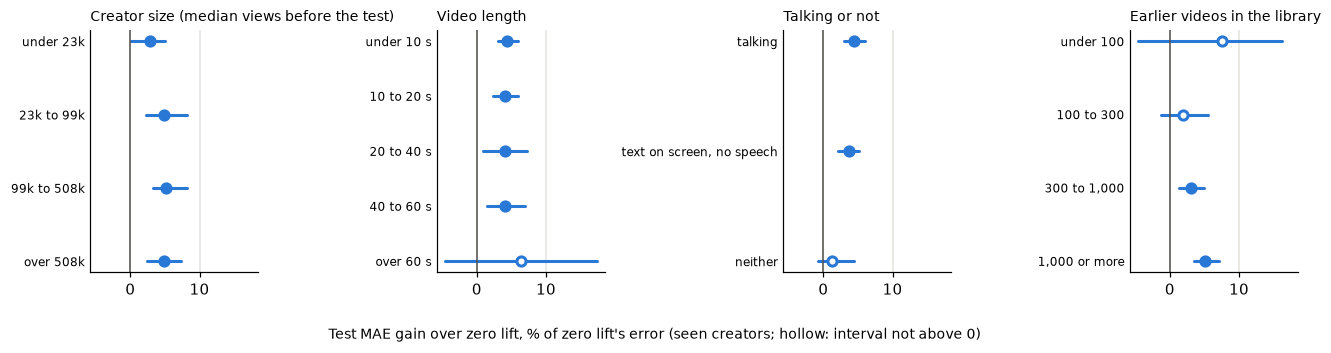

In [18]:
fig, axes = plt.subplots(1, len(CUTS), figsize=(12, 3.2), sharex=True)
for ax, (cut, bins) in zip(axes, slices.items()):
    shown = [(label, s) for label, s in bins.items() if "gain" in s]
    for y, (label, s) in enumerate(reversed(shown)):
        r, base = s["gain"], s["zero lift"]
        ax.plot([100 * r.gain_low / base, 100 * r.gain_high / base], [y, y], color=BLUE, linewidth=2,
                solid_capstyle="round")
        ax.plot(100 * r.gain / base, y, "o", markersize=6, markeredgewidth=2, color=BLUE,
                markerfacecolor=BLUE if r.gain_low > 0 else "white")
    ax.set_yticks(range(len(shown)), [label for label, _ in reversed(shown)], fontsize=8)
    ax.axvline(0, color=MUTED, linewidth=1)
    ax.grid(axis="x", color=GRID, linewidth=1)
    ax.set_axisbelow(True)
    ax.tick_params(axis="y", length=0)
    ax.set_title(cut, loc="left", fontsize=9)
fig.supxlabel("Test MAE gain over zero lift, % of zero lift's error (seen creators; hollow: interval not above 0)",
              fontsize=9)
fig.tight_layout()
plt.show()

## 13. Five findings, each one changing a decision

Each finding below changed what was built next. Stage 1's come from notebook 01, the rest from the
notebooks named; the test numbers are section 11's.

1. **The creator explains 38% of the variance in log share rate** (stage 1). *Decision:* the target is lift, each video
   against its own creator's recent median, and creators the model trained on are reported apart from creators it never
   saw. Without it, a model would mostly learn who made the video.
2. **Share rate drifted 4.7× inside the same creators between 2022 and 2026** (stage 1). *Decision:* the baseline is the
   median of the creator's last 30 settled videos, not their lifetime; the splits are by time; and the test is the newest
   videos, April to September 2026.
3. **The platform keeps each channel's winners:** kept clips beat their creator's median 64% of the time, retired ones
   43%, and on validation whether a clip's file still exists beats the final honest model (+0.0191 against +0.0159 over
   zero lift, seen creators). *Decision:* no `files` column is ever a feature, every frame comes out of the platform's
   own poster code, and every model here is checked for finding kept clips (stages 1, 2, 4, 5).
4. **A first frame names its creator 65% of the time, and adds nothing beyond the words** (stage 4; on the test,
   +0.0004 [−0.0002, +0.0009]). *Decision:* nothing was fine-tuned, no second GPU was rented, and the final model has no
   pixels. What a picture tells about lift here was already in the words, the on-screen text and the scene description.
5. **Recent form misses alone, and next to the words it carries a third of the final gain** (stage 5; on the test,
   +0.0054 [+0.0027, +0.0086] on top of the metadata and the words, for unseen creators too). *Decision:* the final
   model stacks the creator's recent run with what the video says. Of the two, only the words are the creator's to
   change before posting, which is what a page can let a visitor try.

## 14. The report, written by code

**What.** Every number the README and the page will use, gathered into one dict and saved by `sharerate.report.write` as
`reports/results.json`, with `reports/results.md` rendered from that JSON alone:

- the test: every frozen model, every metric, for seen and unseen creators (and the new and held-out ones apart), each
  with its gain over zero lift;
- the claims: each stage's gain over the model before it, on validation and on the test;
- validation: every model three ways against zero lift, with `has_video` as the labelled leak, for the page's chart of
  what clears the bar;
- the ablation and the four cuts of section 12;
- stage 1's headline numbers, read by code from notebook 01's printed outputs (`report.notebook_number`, which stops the
  run if one is gone), and the target's counts from the loader;
- `reports/frozen.json`'s choices.

**Why.** Rule 8: every number in the README, a report or the site comes from a run or from a named file, and reports
are written by code. One file for everything means the README, the page and this notebook can't drift apart.

**The mistake it avoids.** A number typed by hand into a README, or copied from an earlier draft. The Markdown has no
number that isn't in the JSON (`tests/test_report.py`), and the JSON has none that wasn't computed here or read from a
named notebook. Nothing in it is about one creator: each number covers at least 5.

In [19]:
NAMES = {"B0 zero lift": "zero lift (the creator's recent median)", "B3 ridge": "metadata (B3 ridge)",
         "B1 recent form": "recent form (B1)", "4B ridge": "metadata and the words (4B ridge)",
         "image ridge": "metadata, the words and the first frame (image ridge)",
         "combined": "metadata, the words and recent form (the combined model)",
         "4B logistic": "the words' breakout head (4B logistic, ranking only)",
         "has_video (a LEAK, not a model)": "whether the platform kept the clip (a leak, never a model)"}
leak_means = pd.Series(lift[training]).groupby(kept[training]).mean()  # notebook 02, cell 33: kept and retired clips
every["has_video (a LEAK, not a model)"] = leak_means.reindex(kept).to_numpy()
VALIDATION_MODELS = ["B0 zero lift", "B3 ridge", "B1 recent form", "4B ridge", "image ridge", "combined",
                     "has_video (a LEAK, not a model)"]


def as_scores(table, rows, who):
    # A score_table as {model: {metric: score}}, each with the rows it was scored on
    n_videos, n_creators = int(rows.sum()), len(set(who[rows]))
    out = {}
    for r in table.itertuples():
        out.setdefault(r.model, {})[r.metric] = report.score(r._asdict(), n_videos, n_creators)
    return out


def counted(r, rows, who):
    return report.score(r, rows.sum(), len(set(who[rows])))


NB01 = data.ROOT / "notebooks" / "01_eda_target.ipynb"
first, last = everything.published_at[test].min(), everything.published_at[test].max()
results = {
    "about": {"notebook": "notebooks/05_results.ipynb", "snapshot": data.FROZEN_SNAPSHOT, "draws": N_BOOT, "seed": SEED,
              "min_creators": MIN_CREATORS, "interval": "95%, from draws of creators, paired for gains"},
    "data": {"videos": len(everything), "creators": int(everything.creator.nunique()),
             "breakout_rate": float(everything.breakout.mean()),
             "test_period": f"posted {first.day} {first:%B %Y} to {last.day} {last:%B %Y}",
             "splits": {split: {g: {"videos": int(((everything.time_split == split) & (everything.creator_seen == g)).sum()),
                                    "creators": int(everything.creator[(everything.time_split == split)
                                                                       & (everything.creator_seen == g)].nunique())}
                                for g in GROUPS} for split in data.SPLITS}},
    "final_model": FINAL, "models": NAMES, "metrics": list(METRICS), "test_models": TEST_MODELS,
    "validation_models": VALIDATION_MODELS,
    "test": {g: as_scores(test_tables[g], rows, who_test) for g, rows in TEST_GROUPS.items()},
    "validation": {g: as_scores(score_table({m: every[m] for m in VALIDATION_MODELS}, validation & (group == g),
                                            base="B0 zero lift"), validation & (group == g), creator) for g in GROUPS},
    "claims": {claim: {"model": c["model"], "base": c["base"], "rows": c["rows"],
                       "validation": {"seen": counted(c["validation"], c["validation_rows"], creator)},
                       "test": {label: counted(r, c["test_rows"][label], who_test) for label, r in c["test"].items()},
                       "holds": bool(c["holds"]), "holds unseen": bool(c["holds unseen"])}
               for claim, c in claims.items()},
    "ablation": {"combiner": COMBINER, "rows": "validation, seen creators",
                 "subsets": {name: counted(ablation_table.loc[name], seen_rows, creator) for name in ablation}},
    "slices": {cut: {label: (counted(s["gain"], seen_test & (CUTS[cut][0] == label), who_test) if "gain" in s
                             else {"videos": s["videos"], "creators": s["creators"]})
                     for label, s in bins.items()} for cut, bins in slices.items()},
    "stage1": {"source": "notebooks/01_eda_target.ipynb",
               "creator_variance_share": report.notebook_number(NB01, r"Knowing only the creator explains (\d+)%") / 100,
               "drift_factor": report.notebook_number(NB01, r"changed by ([\d.]+)x \(median\)"),
               "settled_rate_change": report.notebook_number(NB01, r"15-30\s+932\s+64\s+[\d.]+\s+([\d.]+)") - 1,
               "kept_above_median": report.notebook_number(NB01, r"file still on disk\s+\d+\s+([\d.]+)"),
               "retired_above_median": report.notebook_number(NB01, r"file retired\s+\d+\s+([\d.]+)")},
    "frozen": frozen,
}
json_path, md_path = report.write(results)
print(f"Wrote {json_path.relative_to(data.ROOT)} ({json_path.stat().st_size:,} bytes) and "
      f"{md_path.relative_to(data.ROOT)} ({md_path.stat().st_size:,} bytes)")
print(md_path.read_text(encoding="utf-8").split("### What each part adds")[0])

Wrote reports\results.json (83,026 bytes) and reports\results.md (10,269 bytes)
# Results

Written by `notebooks/05_results.ipynb` from its own runs; every number below is in `results.json` beside this file. Intervals are 95%, from 2,000 draws of creators (seed 2026), paired where they are gains. Lift is log10 of the share rate minus the creator's recent median, so an MAE of 0.37 is a factor of 10^0.37 = 2.3 either way. A gain is the base's error minus the model's: positive is better.

## The result, on the test split (opened once)

The final model is **metadata, the words and recent form (the combined model)**. On the newest videos (posted 1 April 2026 to 18 September 2026), for creators it trained on (12,455 videos from 138 creators), predicting zero lift misses by 0.3752 log10, a factor of 2.37 either way. The final model misses by 0.3595: a gain of +0.0157 [+0.0109, +0.0210], an error 4.2% smaller. For creators it never saw (9,285 videos from 81 creators), zero lift misses by 0.377

## What stage 5 found

- **Everything together beats every part, on the test.** For creators the model trained on, the creator's
  recent median misses a video's share rate by 0.3752 log10, a factor of 2.37 either way. The combined model, the
  metadata, the words and recent form in a linear stack, misses by 0.3595: +0.0157 [+0.0109, +0.0210], an error 4.2%
  smaller. For creators it never saw: +0.0123 [+0.0069, +0.0181], 3.3%.
- **Validation priced it right.** Every claim's test gain is within 0.0002 of its validation gain for seen creators, and
  the claim that missed on validation, the frame, misses on the test.
- **Recent form earns its place next to the words.** Alone it missed stage 2's bar. Stacked with the words (weights
  0.94 and 1.02), it adds +0.0054 [+0.0027, +0.0086] on the test, for unseen creators too (+0.0056), and lifts the
  Spearman inside a creator from 0.244 to 0.303.
- **It ranks a creator's videos.** Of each seen creator's top tenth by the model, 43.5% broke out (at least twice the
  creator's median), against 25.3% for a random pick; ROC-AUC 0.633.
- **Where it works:** evenly across lengths and creator sizes, weakest for the smallest creators (2.9% of the error) and
  for videos with no words at all (1.3%, interval across 0), strongest for creators with long histories (5.1%).
- **Not a leak.** At the same lift, the combined model rates the clips the platform kept lower, not higher, for a
  mechanical reason (kept clips have higher baselines at the same lift, and recent form subtracts the baseline), and it
  ranks videos among kept clips alone and among retired clips alone.
- **Still small.** The typical miss goes from a factor of 2.37 to 2.29. How a video does against its creator's recent
  median is mostly not predictable from what is known before it is posted, and the 4% that is comes from what the video
  says and how the creator has been doing.

The test split was opened once, in section 11, on the models `reports/frozen.json` froze before it.

## The hand-off

- **To the README:** stage 5's row, "What stage 5 found" and the result, from `reports/results.md`, and stage 6's row,
  which can no longer be a FastAPI endpoint (below).
- **To going public:** `reports/results.json`, `results.md` and `frozen.json` go public with the code. They
  hold aggregates only, each over at least 5 creators, and no username, video id, caption or transcript.
- **To the page:** every number comes from `reports/results.json`: the test table, the claims beside
  validation, the ablation, the four cuts and stage 1's numbers. The reported model can't run in a browser: its words
  need Qwen3-Embedding-4B (16 GB in float32), and its recent form needs the creator's settled share rates, which a
  visitor doesn't have. A "type a hook" demo would run bge-small, whose gain is validation's (+0.0082 over B3: its test
  texts were never embedded), and must say it is a weaker model than the one reported.
- **The test is spent.** A new model needs a new test: the 188 creators with no counts (trap 6), fetched later, would
  come with splits of their own.